# Лабораторная работа №4
## Случайный лес

В этой работе я исследую случайный лес для классификации кредитных заявок и прогноза
прочности бетона. Продолжаю исследования №1–3: данные, цели, train/test, CV-фолды
и метрики сохраняются. Сначала получу исходные результаты sklearn, проверю гипотезы
на обучающей выборке, затем самостоятельно реализую лес и перенесу найденные улучшения.

| Задача | Модель | Цель | Основная метрика |
|:--|:--|:--|:--|
| Историческое одобрение заявки | RandomForestClassifier, Gini | `loan_status` | F1 ↑ |
| Прочность новой рецептуры | RandomForestRegressor, squared_error | `strength`, МПа | MAE ↓ |

Для каждой задачи сравню **четыре варианта**: исходный и улучшенный sklearn,
исходную и улучшенную свою реализацию. Dummy даёт простой ориентир.
Обучение выполняется на всех **36 000** заявок и **799** измерениях бетона;
отложенная проверка — **9 000** и **206** строк соответственно.

**Ход исследования:**
1. Данные, практическая задача, метрики и протокол.
2. Бейзлайн sklearn и оценка качества.
3. Гипотезы, CV, подбор параметров и улучшенный бейзлайн.
4. Собственная реализация, исходные модели и перенос улучшений.
5. OOB, устойчивость, ошибки, важности и сравнение с №1–3.
6. Выводы, ограничения и воспроизводимость.

Таблицы, графики, исходный код алгоритма и численные выводы сохранены в notebook
для просмотра на GitHub. Отдельная общая сводка — [comparison.ipynb](../comparison.ipynb).

---

### Почему выбраны эти задачи

**Классификация.** По сведениям о клиенте и запрошенном кредите предсказываю историческое
одобрение заявки: `loan_status=1` — одобрено, `0` — отказ.
Такая задача подходит для предварительной оценки заявок. Из входов исключаю цель
и `loan_int_rate`, поскольку прогноз нужен до назначения ставки.
Доход, сумма и их отношение считаю известными на момент подачи заявки.
Сочетание числовых и категориальных признаков позволяет проверить пороговые правила
и нелинейные взаимодействия в ансамбле деревьев. Набор синтетический; одобрение не равно будущему дефолту.

**Регрессия.** По составу смеси и возрасту предсказываю прочность бетона в МПа.
Это помогает предварительно оценивать рецептуры и планировать испытания.
Связь прочности с возрастом и составом может быть нелинейной, поэтому интересно проверить,
насколько хорошо дерево опишет её пороговыми правилами и признаками состава.
Цель `strength` не входит в признаки и не преобразуется.

### Какие признаки используются

В кредитном наборе 45 000 строк и 14 столбцов. После исключения цели и ставки остаётся
12 входных признаков: 7 числовых и 5 категориальных.

| Признак | Смысл |
|:--|:--|
| `person_age` | Возраст клиента, годы |
| `person_gender` | Пол |
| `person_education` | Уровень образования |
| `person_income` | Годовой доход |
| `person_emp_exp` | Стаж работы, годы |
| `person_home_ownership` | Тип владения жильём |
| `loan_amnt` | Запрашиваемая сумма кредита |
| `loan_intent` | Цель кредита |
| `loan_percent_income` | Отношение суммы кредита к доходу |
| `cb_person_cred_hist_length` | Длительность кредитной истории, годы |
| `credit_score` | Кредитный рейтинг |
| `previous_loan_defaults_on_file` | Наличие прошлых дефолтов |
| `loan_int_rate` | Процентная ставка; исключаю из входов |
| `loan_status` | Цель: 1 — одобрено, 0 — отказ |

Единицы дохода и суммы кредита в доступном описании отдельно не уточняются,
поэтому трактую их как денежные величины в одной шкале.

В наборе бетона 1030 строк, 8 входных признаков и одна целевая переменная.

| Признак | Смысл | Единицы |
|:--|:--|:--|
| `cement` | Цемент | кг/м³ |
| `slag` | Доменный шлак | кг/м³ |
| `fly_ash` | Зола-унос | кг/м³ |
| `water` | Вода | кг/м³ |
| `superplasticizer` | Суперпластификатор | кг/м³ |
| `coarse_aggregate` | Крупный заполнитель | кг/м³ |
| `fine_aggregate` | Мелкий заполнитель | кг/м³ |
| `age` | Возраст образца | дни |
| `strength` | Цель: прочность при сжатии | МПа |

Оба исходных набора не содержат пропусков. Заполнение пропусков всё равно включаю
в Pipeline как часть подготовки. После удаления 25 полных дубликатов бетона
остаётся 1005 измерений: **799 строк и 342 рецептуры в train**, **206 строк и 86 рецептур в test**.
Кредитный набор не содержит полных дубликатов; train/test — **36 000 / 9 000** строк.


### Как понимать метрики

Основные показатели считаю по формулам:

$$F_1=\frac{2TP}{2TP+FP+FN},\qquad
  MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|.$$

Здесь TP — правильно предсказанные одобрения, FP — ошибочные одобрения,
FN — пропущенные одобрения. В кредитных данных класс 1 составляет около 22,2%,
поэтому одной accuracy недостаточно. F1 помогает одновременно учитывать точность и полноту,
а MAE показывает ошибку прочности в понятных единицах — МПа.

| Дополнительная метрика | Что показывает |
|:--|:--|
| Precision | Какая доля предсказанных одобрений действительно относится к классу 1 |
| Recall | Какая доля реальных одобрений найдена моделью |
| Accuracy | Доля правильных ответов среди всех заявок |
| Balanced accuracy | Средняя полнота по двум классам, с одинаковым вкладом каждого класса |
| ROC-AUC | Насколько хорошо вероятности ранжируют классы при разных порогах; случайный ориентир — 0,5 |
| Average precision (AP) | Качество ранжирования через precision и recall; ориентир случайного ранжирования — доля класса 1 |
| RMSE | Корень средней квадратичной ошибки в МПа; сильнее реагирует на крупные промахи |
| R² | $1-\sum(y_i-\hat y_i)^2/\sum(y_i-\bar y)^2$; сравнение с постоянным прогнозом среднего, может быть отрицательным |

В сравнении разных алгоритмов для одной задачи использую один и тот же набор метрик.
F1 и ошибки прочности между собой не складываю: они относятся к разным задачам.


### Источники и выбор данных

Автор кредитного набора — **taweilo**,
[страница Loan Approval на Kaggle](https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data).
В работе использую CSV из [публичной копии с фиксированным commit](https://github.com/dpidaparthi/loan-approval-classification/blob/379a24f61cd5d9f032415b14a5797f30cf1d4a05/data/loan_data.csv).
Побайтовое совпадение с загрузкой Kaggle не проверено: контрольная сумма в коде относится
к этой копии. По описанию автора набор синтетический, с расширением SMOTENC.
Условия использования задаются источником Kaggle; отдельную лицензию на данные я не назначаю.

Набор бетона: **Yeh, I. (1998), Concrete Compressive Strength**,
[UCI №165, DOI 10.24432/C5PK67](https://doi.org/10.24432/C5PK67).
Использую исходный XLS из [официального архива UCI](https://archive.ics.uci.edu/static/public/165/concrete+compressive+strength.zip),
лицензия — [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

При подготовке первой работы выбор сверялся с
[таблицей группы](https://docs.google.com/spreadsheets/d/1szg1vYr3MLq8eqCejGbvVOdF7t87slb3h2x8qv2e-So/edit?gid=0)
**10 ноября 2026 года**. В сохранённой проверке учтено 20 записей,
совпадений выбранных наборов с другими студентами не найдено.
Это результат сверки на указанную дату, а не повторная проверка текущего состояния таблицы.

### Как устроен случайный лес

Случайный лес объединяет $B$ деревьев CART. Для каждого дерева независимо выбирается
bootstrap-выборка из $n$ строк train **с возвращением**, а в каждом узле ищется лучшее
разбиение по случайному подмножеству из $m$ признаков. Это два разных источника случайности.
Случайное подмножество обновляется **в каждом узле**, а не один раз на дерево.

В классификации использую подход sklearn: усредняю распределения классов в листьях,
затем выбираю класс максимальной средней вероятности:
$$\hat p_k(x)=\frac1B\sum_{b=1}^{B}p_{bk}(x),\qquad
\hat y(x)=\operatorname{argmax}_k\hat p_k(x).$$
Для двух классов это порог 0,5; при равенстве выбираю первый класс, то есть 0.
Усреднение вероятностей может отличаться от большинства жёстких голосов отдельных деревьев.
В регрессии прогноз — среднее значений листьев:
$$\hat y(x)=\frac1B\sum_{b=1}^{B}T_b(x).$$

Дерево классификации минимизирует взвешенную нечистоту Gini:
$$G(t)=1-\sum_k p_{tk}^2,\qquad
\Delta(t)=W_tG(t)-W_LG(L)-W_RG(R).$$
Для регрессии выбираю порог с минимальной суммой квадратов отклонений в двух дочерних узлах:
$$SSE(L,R)=\sum_{i\in L}(y_i-\bar y_L)^2+\sum_{i\in R}(y_i-\bar y_R)^2.$$
Выбор MAE для оценки не означает, что дерево обучается по MAE: критерий обучения — squared_error.

Если отдельные деревья имеют одинаковую дисперсию $\sigma^2$ и попарную корреляцию $\rho$,
то дисперсия среднего равна
$$\operatorname{Var}(\bar T)=\sigma^2\left(\rho+\frac{1-\rho}{B}\right).$$
Это поясняющая модель, а не измеренная формула ошибки наших данных: увеличение числа деревьев
уменьшает случайную часть, а снижение корреляции требует разнообразия деревьев.
Слишком маленькое `max_features` может ослабить сами деревья, поэтому эффект проверю по CV.

В bootstrap из $n$ вытягиваний ожидаемая доля уникальных строк равна
$1-(1-1/n)^n\approx0{,}632$. Строка остаётся **out-of-bag (OOB)** с вероятностью
$(1-1/n)^n\approx0{,}368$. Для OOB-прогноза строки усредняются только деревья,
которые её не видели. При малом числе деревьев OOB-прогноз может отсутствовать.

Математика ансамбля опирается на [Breiman, Random Forests (2001)](https://www.stat.berkeley.edu/~breiman/randomforest2001.pdf).
Принятые параметры, усреднение вероятностей и стандартные OOB-метрики описаны в
[документации RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
и [RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html).

## 1. Подготовка данных

Зафиксирую seed, версии библиотек и один поток вычислений, как в предыдущих работах.
Таблицы оформлю в том же стиле: русские подписи, четыре знака после запятой,
согласованные цвета. Файлы результатов записываются только в `lab_4/results`.

In [1]:
# Настройки окружения задаются до импорта NumPy для воспроизводимых измерений времени.
import os
for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[variable] = "1"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/vkr_matplotlib")
import sys
import json
import platform
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
ROOT = Path.cwd() if (Path.cwd() / "lab_1").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "lab_4" / "results"
RESULTS.mkdir(parents=True, exist_ok=True)
thread_limit = threadpool_limits(limits=1)
sns.set_theme(style="whitegrid")
print({"python": platform.python_version(), "numpy": np.__version__,
       "pandas": pd.__version__, "sklearn": sklearn.__version__})

# Общий стиль таблиц и графиков.
MODEL_NAMES = {
    "sklearn_baseline": "sklearn · исходная",
    "sklearn_improved": "sklearn · улучшенная",
    "custom_baseline": "своя · исходная",
    "custom_improved": "своя · улучшенная",
    "dummy": "Dummy",
}
TASK_NAMES = {"classification": "Классификация", "regression": "Регрессия"}
COLUMN_NAMES = {
    "model": "Модель", "task": "Задача", "lab": "Работа", "dataset": "Набор данных",
    "algorithm": "Алгоритм", "implementation": "Реализация", "stage": "Вариант",
    "f1": "F1 ↑", "precision": "Precision", "recall": "Recall",
    "accuracy": "Accuracy", "balanced_accuracy": "Balanced accuracy",
    "roc_auc": "ROC-AUC", "average_precision": "AP", "mae": "MAE, МПа ↓",
    "rmse": "RMSE, МПа ↓", "r2": "R² ↑", "fit_seconds": "Обучение, с",
    "predict_seconds": "Прогноз, с", "mode": "Признаки", "representation": "Признаки",
    "cv_mean": "Среднее CV", "cv_std": "Разброс CV", "mean_test_score": "Среднее CV",
    "std_test_score": "Разброс CV", "rank_test_score": "Место", "status": "Статус",
    "comparison": "Сравнение", "delta": "Изменение", "metric": "Метрика",
    "estimator": "Алгоритм", "n_iter": "Итерации", "gradient_norm": "Норма градиента",
    "objective": "Функция потерь", "missing_train": "Пропуски", "dtype": "Тип",
    "missing": "Пропуски", "unique": "Уникальные", "type": "Тип",
    "param_model__n_neighbors": "Соседи (k)", "param_model__weights": "Веса",
    "param_model__p": "Расстояние (p)", "class_weight": "Веса классов",
    "count": "Количество", "fraction": "Доля", "train_fraction": "Доля в train",
}

def show_table(value, title=None):
    """Вывод таблицы с подписями и одинаковой точностью чисел."""
    if isinstance(value, pd.Series):
        value = value.to_frame()
    if not isinstance(value, pd.DataFrame):
        display(value)
        return
    table = value.copy()
    for column in table.columns:
        table[column] = table[column].map(
            lambda item: MODEL_NAMES.get(item, TASK_NAMES.get(item, item)) if isinstance(item, str) else item)
    table = table.rename(columns=COLUMN_NAMES)
    styled = table.style.format(precision=4, na_rep="—").set_table_styles([
        {"selector": "th", "props": [("background-color", "#edf3f8"), ("color", "#243b53"),
                                     ("padding", "9px 12px"), ("text-align", "left")]},
        {"selector": "td", "props": [("padding", "7px 12px"), ("border-bottom", "1px solid #e8edf2")]},
        {"selector": "caption", "props": [("caption-side", "top"), ("text-align", "left"),
                                          ("font-weight", "600"), ("padding", "10px 0")]},
    ])
    if isinstance(table.index, pd.RangeIndex):
        styled = styled.hide(axis="index")
    if title:
        styled = styled.set_caption(title)
    if "Норма градиента" in table.columns:
        styled = styled.format({"Норма градиента": "{:.2e}"})
    display(styled)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "grid.alpha": 0.25, "axes.prop_cycle": plt.cycler(color=["#387ca3", "#db9655", "#4c9c8a", "#9c7cb5"]),
})
# Подписи показателей сложности дерева и результатов поиска.
COLUMN_NAMES.update({"max_depth": "Предел глубины", "min_samples_leaf": "Минимум в листе",
                     "depth": "Глубина", "leaves": "Листья", "nodes": "Узлы",
                     "mean_train_score": "Среднее train", "train_score": "Качество train"})
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, mean_absolute_error
COLUMN_NAMES.update({"n_estimators": "Деревьев", "max_features": "Признаки в узле",
                     "max_samples": "Размер bootstrap", "bootstrap": "Bootstrap",
                     "oob_coverage": "Покрытие OOB", "oob_primary": "OOB F1 / MAE",
                     "depth_mean": "Средняя глубина", "total_nodes": "Всего узлов",
                     "seed": "Seed", "mean_train_score": "Среднее train"})

{'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.1.1', 'sklearn': '1.9.1'}


### Общий протокол и контроль разбиений

Ниже показаны общие функции из предыдущих работ: проверка SHA256 файлов, чтение,
формирование признаков, метрики и восстановление train/test. Их повторное использование
сохраняет сопоставимость. `load_tasks` дополнительно проверяет отсутствие пересечения
рецептур бетона на holdout и каждом CV-фолде.

Все обучаемые преобразования — заполнение пропусков, one-hot и при необходимости scaling —
обучаются внутри Pipeline на обучающей части фолда. Признаки-отношения не используют цель.
Удаление полных дубликатов и правила группировки зафиксированы ещё в №1.

In [2]:
# Общие функции доступны прямо в notebook; версии для повторного использования лежат в src.
"""Два датасета, общий протокол, признаки и метрики лабораторной №1."""

import hashlib
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             average_precision_score, mean_absolute_error,
                             root_mean_squared_error, r2_score)

SEED = 42
CATEGORICAL = ["person_gender", "person_education", "person_home_ownership",
               "loan_intent", "previous_loan_defaults_on_file"]
CONCRETE_COLUMNS = ["cement", "slag", "fly_ash", "water", "superplasticizer",
                    "coarse_aggregate", "fine_aggregate", "age", "strength"]
DATASETS = {
    "classification": {
        "name": "Loan Approval Classification Data", "file": "loan_data.csv",
        "sha256": "67cca604cd71cbd605014f721d078d20d44d726d625945591450733535f9868a",
        "target": "loan_status", "excluded": ["loan_status", "loan_int_rate"],
        "protocol_id": "loan-v1-seed42-test20", "expected_shape": (45000, 14),
    },
    "regression": {
        "name": "Concrete Compressive Strength", "file": "Concrete_Data.xls",
        "sha256": "710076c66b9ca3f8050e7942f3dcbdbe04013534daeb0077ffd3079a52d8e0c4",
        "target": "strength", "excluded": ["strength"],
        "protocol_id": "concrete-v1-recipe-groups-seed42-test20", "expected_shape": (1030, 9),
    },
}
EXCLUDED = {task: spec["excluded"] for task, spec in DATASETS.items()}


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def load_dataset(lab, task):
    """Чтение исходного файла с проверкой SHA256; y не меняется."""
    spec = DATASETS[task]
    path = Path(lab) / "data" / "raw" / spec["file"]
    if sha256(path) != spec["sha256"]:
        raise ValueError(f"Контрольная сумма {path.name} не совпала")
    if task == "classification":
        frame = pd.read_csv(path)
    else:
        # Подавляем только сообщение о будущем удалении xlrd из pandas, не ошибки данных.
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="The xlrd engine is deprecated.*")
            frame = pd.read_excel(path, engine="xlrd")
        frame.columns = CONCRETE_COLUMNS
    if frame.shape != spec["expected_shape"]:
        raise ValueError(f"Неожиданная форма {path.name}: {frame.shape}")
    return frame


class TaskFeatures(TransformerMixin, BaseEstimator):
    """Детерминированные признаки: не используют y и статистики test."""
    def __init__(self, task="classification", mode="raw"):
        self.task = task
        self.mode = mode

    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        result = X.copy()
        if self.mode in ("log", "engineered"):
            column = "person_income" if self.task == "classification" else "age"
            result[column] = np.log1p(result[column].clip(lower=0))
        if self.mode == "engineered":
            if self.task == "classification":
                result["employment_age_ratio"] = X["person_emp_exp"] / X["person_age"].clip(lower=1)
                result["credit_history_age_ratio"] = X["cb_person_cred_hist_length"] / X["person_age"].clip(lower=1)
            else:
                binder = (X["cement"] + X["slag"] + X["fly_ash"]).clip(lower=1e-12)
                result["binder"] = binder
                result["water_binder_ratio"] = X["water"] / binder
                result["aggregate_binder_ratio"] = (X["coarse_aggregate"] + X["fine_aggregate"]) / binder
        return result




def evaluate(task, truth, prediction, probabilities=None):
    if task == "classification":
        return {
            "f1": f1_score(truth, prediction, zero_division=0),
            "precision": precision_score(truth, prediction, zero_division=0),
            "recall": recall_score(truth, prediction, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(truth, prediction),
            "accuracy": accuracy_score(truth, prediction),
            "roc_auc": roc_auc_score(truth, probabilities),
            "average_precision": average_precision_score(truth, probabilities),
        }
    return {"mae": mean_absolute_error(truth, prediction),
            "rmse": root_mean_squared_error(truth, prediction),
            "r2": r2_score(truth, prediction)}

def load_tasks(root):
    """Читаем сохранённые разбиения №1, проверяя SHA, полноту и группы."""
    lab = root / "lab_1"
    protocol = json.loads((lab / "results" / "protocol.json").read_text())
    tasks = {}
    for task, spec in DATASETS.items():
        raw = load_dataset(lab, task)
        data = raw.drop_duplicates()
        path = lab / "results" / f"split_{task}.csv"
        reference = protocol["datasets"][task]
        if sha256(path) != reference["split_sha"]:
            raise ValueError(f"Изменилось разбиение {task}")
        split = pd.read_csv(path)
        assert not split.row_id.duplicated().any()
        assert set(split.row_id) == set(data.index)
        assert set(split.split) == {"train", "test"}
        train = split.loc[split.split == "train", "row_id"].to_numpy()
        test = split.loc[split.split == "test", "row_id"].to_numpy()
        X, y = data.drop(columns=spec["excluded"]), data[spec["target"]]
        assert list(X.columns) == reference["features"]
        if task == "regression":
            groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X.drop(columns="age")))[0], index=X.index)
        else:
            groups = pd.Series(X.index, index=X.index)
        np.testing.assert_array_equal(groups.loc[split.row_id], split.group_id)
        assert set(groups.loc[train]).isdisjoint(groups.loc[test])
        if task == "classification":
            folds = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(X.loc[train], y.loc[train]))
        else:
            folds = list(GroupKFold(3).split(X.loc[train], y.loc[train], groups.loc[train]))
        for a, b in folds:
            assert set(groups.loc[train].iloc[a]).isdisjoint(groups.loc[train].iloc[b])
        tasks[task] = dict(X_train=X.loc[train], X_test=X.loc[test],
                           y_train=y.loc[train], y_test=y.loc[test], cv=folds,
                           split=split, spec=spec, split_sha=sha256(path),
                           duplicates_removed=len(raw) - len(data))
    return tasks

### Обучающая и тестовая выборки

Сохраню копии идентификаторов разбиений и назначения CV-фолдов. Классификация использует
`StratifiedKFold(3, shuffle=True, random_state=42)`, регрессия — `GroupKFold(3)` по рецептурам.
Статистики признаков ниже считаются только по train.

In [3]:
# load_tasks восстанавливает порядок train/test из CSV первой работы и проверяет группы.
tasks = load_tasks(ROOT)
fold_records = []
for task, t in tasks.items():
    t["split"].to_csv(RESULTS / f"split_{task}.csv", index=False)
    for fold, (train_fold, valid_fold) in enumerate(t["cv"]):
        for subset, positions in [("train", train_fold), ("validation", valid_fold)]:
            fold_records.extend({"task": task, "fold": fold, "subset": subset, "row_id": int(row)}
                                for row in t["X_train"].index[positions])
    print(f"{TASK_NAMES[task]}: train — {len(t['X_train'])}, test — {len(t['X_test'])}.")
    show_table(pd.DataFrame({"dtype": t["X_train"].dtypes.astype(str),
                          "missing_train": t["X_train"].isna().sum()}))
pd.DataFrame(fold_records).to_csv(RESULTS / "cv_folds.csv", index=False)
scoring = {"classification": "f1", "regression": "neg_mean_absolute_error"}

Классификация: train — 36000, test — 9000.


,Тип,Пропуски
person_age,float64,0
person_gender,str,0
person_education,str,0
person_income,float64,0
person_emp_exp,int64,0
person_home_ownership,str,0
loan_amnt,float64,0
loan_intent,str,0
loan_percent_income,float64,0
cb_person_cred_hist_length,float64,0


Регрессия: train — 799, test — 206.


,Тип,Пропуски
cement,float64,0
slag,float64,0
fly_ash,float64,0
water,float64,0
superplasticizer,float64,0
coarse_aggregate,float64,0
fine_aggregate,float64,0
age,int64,0


### Разведочный анализ train

Проверю дисбаланс классов, диапазоны состава и распределения возраста и дохода.
Длинный хвост дохода мотивирует проверку log-преобразования; зависимость прочности
от возраста и состава — создание отношений компонентов. Для леса изменение масштаба
не должно давать систематического выигрыша, поэтому scaling послужит контрольной гипотезой.

,Количество,Доля
loan_status,,
0,28000,0.7778
1,8000,0.2222


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
count,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000
mean,277.6300,70.2200,55.9300,182.5500,5.8200,974.0500,772.9600,47.5800,34.9700
std,102.5000,87.4000,63.9700,21.4300,5.7100,73.8100,83.1400,67.0100,15.8100
min,108.3000,0.0000,0.0000,121.7500,0.0000,801.0000,594.0000,1.0000,2.3300
25%,192.0000,0.0000,0.0000,166.6100,0.0000,932.0000,716.9500,14.0000,23.6600
50%,266.0000,15.0000,0.0000,185.7000,6.0000,968.0000,780.5800,28.0000,33.7200
75%,339.0000,137.1000,117.5400,193.0000,9.9000,1025.0000,829.7500,56.0000,44.4700
max,540.0000,359.4000,200.1000,246.9000,32.2000,1125.0000,992.6000,365.0000,80.2000


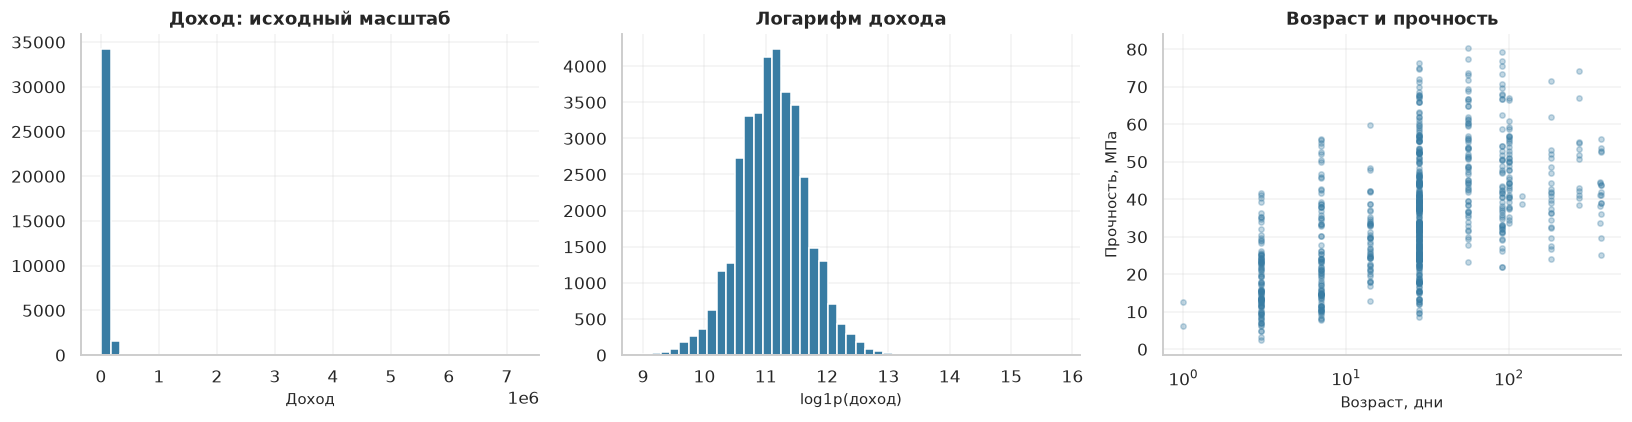

In [4]:
# EDA не обращается к отложенной выборке; справочные распределения строятся только на train.
c, r = tasks["classification"], tasks["regression"]
show_table(c["y_train"].value_counts().rename("count").to_frame().assign(
    fraction=c["y_train"].value_counts(normalize=True)))
show_table(r["X_train"].join(r["y_train"]).describe().round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(c["X_train"]["person_income"], bins=45)
axes[0].set(title="Доход: исходный масштаб", xlabel="Доход")
axes[1].hist(np.log1p(c["X_train"]["person_income"].clip(lower=0)), bins=45)
axes[1].set(title="Логарифм дохода", xlabel="log1p(доход)")
axes[2].scatter(r["X_train"]["age"], r["y_train"], s=12, alpha=.3)
axes[2].set(xscale="log", xlabel="Возраст, дни", ylabel="Прочность, МПа", title="Возраст и прочность")
plt.tight_layout()
plt.show()

### Связи признаков и крайние значения

Покажу корреляции числовых признаков и крайние значения. Корреляция не доказывает
причинность; её полезно учитывать при интерпретации важностей. Наблюдения не удаляю
по результатам просмотра: сохраняю протокол №1–3 и проверяю регуляризацию леса.

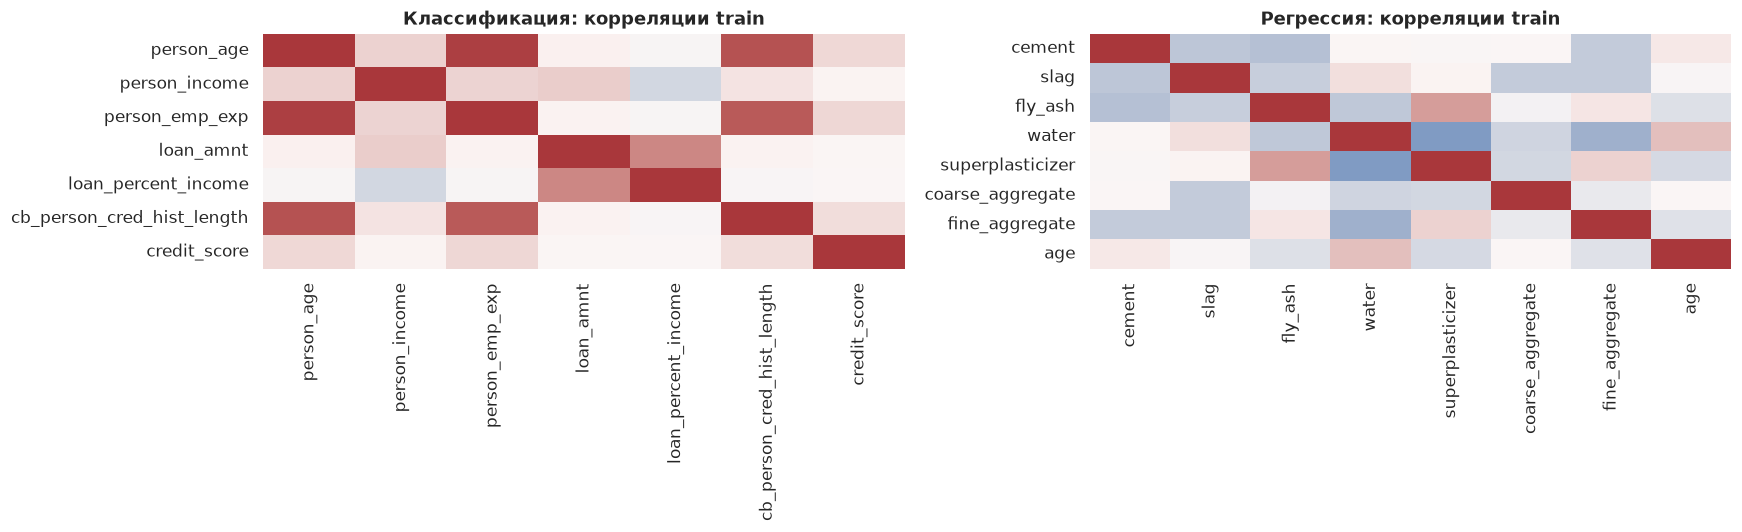

,0.000000,0.010000,0.500000,0.990000,1.000000
person_age,20.0000,21.0000,26.0000,48.0000,144.0000
person_income,8000.0000,17797.9900,67081.0000,274873.8100,7200766.0000
person_emp_exp,0.0000,0.0000,4.0000,26.0000,125.0000
loan_amnt,500.0000,1170.9800,8000.0000,28251.3900,35000.0000
loan_percent_income,0.0000,0.0200,0.1200,0.4000,0.6600
cb_person_cred_hist_length,2.0000,2.0000,4.0000,17.0000,30.0000
credit_score,390.0000,497.0000,640.0000,723.0000,850.0000


In [5]:
# Дополнительная EDA использует только train; heatmap не включает test.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, task in zip(axes, tasks):
    numeric = tasks[task]["X_train"].select_dtypes(include="number")
    sns.heatmap(numeric.corr(), ax=ax, cmap="vlag", center=0, vmin=-1, vmax=1, cbar=False)
    ax.set_title(TASK_NAMES[task] + ": корреляции train")
plt.tight_layout()
plt.show()
show_table(c["X_train"].select_dtypes(include="number").quantile([0, .01, .5, .99, 1]).T,
           "Кредитные признаки: min, 1%, медиана, 99%, max")

### Почему OOB не заменяет выбранную CV

У бетона несколько строк могут относиться к одной смеси в разном возрасте.
Обычный bootstrap исключает строку, но может оставить в дереве **другие строки той же рецептуры**.
Поэтому его OOB не оценивает тот же сценарий, что GroupKFold и holdout новых рецептур.
В кредитном наборе OOB тоже не устраняет возможную зависимость синтетических объектов.

Кроме того, преобразования Pipeline обучаются на всём train перед bootstrap деревьев.
Следовательно, OOB — внутренняя диагностика леса, а не независимая оценка всего Pipeline.
**Все гипотезы и параметры выбираю только по заранее зафиксированной train-CV.**
На CV максимизирую F1 или отрицательную MAE. На таблицах знак явно указан;
стандартное отклонение трёх фолдов не является доверительным интервалом.

## 2. Создание бейзлайна и оценка качества

Исходный лес фиксирую заранее: **100 деревьев**, неограниченная глубина,
`min_samples_split=2`, `min_samples_leaf=1`, bootstrap размера train.
В классификации `max_features='sqrt'`, обычные веса классов;
в регрессии `max_features=1.0`. Категории — полный one-hot, числа — без scaling.
OOB включён для диагностики. Seed=42 и один поток одинаковы во всех основных запусках.

DummyClassifier предсказывает наиболее частый класс; DummyRegressor — медиану.
Его высокая accuracy при F1=0 показывает, почему для одобрения нельзя ограничиться accuracy.

### Pipeline и запись результатов

Использую предобработку дерева из №3. Ниже её код, фабрика случайных лесов и функция
оценки: сохраняются все метрики, истинные ответы, вероятности, время полного Pipeline,
сложность ансамбля и показатели train. Время подбора параметров не входит во время
окончательного fit; измерение одного запуска служит ориентиром.

In [6]:
# Подготовка признаков одинакова для sklearn и собственной модели.
"""Общие разбиения №1–2 и подготовка данных для решающих деревьев."""

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor


def baseline_params(task):
    return dict(n_estimators=100, max_depth=None, min_samples_leaf=1,
                max_features="sqrt" if task == "classification" else 1.0,
                bootstrap=True, max_samples=None, oob_score=True)


def sklearn_model(task, **params):
    cls = RandomForestClassifier if task == "classification" else RandomForestRegressor
    return cls(random_state=SEED, n_jobs=1, **params)


def make_pipeline(X, task, mode="raw", estimator=None):
    if mode not in ("raw", "scaled", "log", "engineered"):
        raise ValueError(f"Неизвестное представление {mode}")
    categorical = [column for column in CATEGORICAL if column in X]
    numeric = [column for column in X if column not in categorical]
    if mode == "engineered":
        numeric += (["employment_age_ratio", "credit_history_age_ratio"] if task == "classification"
                    else ["binder", "water_binder_ratio", "aggregate_binder_ratio"])
    steps = [("impute", SimpleImputer(strategy="median"))]
    if mode == "scaled":
        steps.append(("scale", StandardScaler()))
    transforms = [("numeric", Pipeline(steps), numeric)]
    if categorical:
        transforms.append(("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical))
    return Pipeline([
        ("features", TaskFeatures(task, mode)),
        ("preprocess", ColumnTransformer(transforms, sparse_threshold=0)),
        ("model", sklearn_model(task, **baseline_params(task)) if estimator is None else estimator),
    ])


records, fitted, predictions, complexity = [], {}, {}, []

def fit_evaluate(task, name, model, mode):
    """Обучаю на полном train; test используется для отчётной оценки."""
    print(f"Обучение {task}: {name}", flush=True)
    t = tasks[task]
    started = perf_counter()
    model.fit(t["X_train"], t["y_train"])
    fit_seconds = perf_counter() - started
    started = perf_counter()
    if task == "classification":
        probabilities = model.predict_proba(t["X_test"])
        prediction = model.classes_[probabilities.argmax(axis=1)]
        proba = probabilities[:, 1]
    else:
        prediction, proba = model.predict(t["X_test"]), None
    predict_seconds = perf_counter() - started
    estimator = model.named_steps["model"]
    scores = evaluate(task, t["y_test"], prediction, proba)
    records.append(dict(lab=4, algorithm="Dummy" if name == "dummy" else
                        ("RandomForestClassifier" if task == "classification" else "RandomForestRegressor"),
                        model=name, implementation="custom" if name.startswith("custom") else "sklearn",
                        stage="dummy" if name == "dummy" else name.split("_")[1], task=task,
                        dataset=t["spec"]["name"], target=t["spec"]["target"],
                        feature_set=",".join(t["X_train"].columns), dataset_sha=t["spec"]["sha256"],
                        split_sha=t["split_sha"], protocol_id=t["spec"]["protocol_id"],
                        n_train=len(t["X_train"]), n_test=len(t["X_test"]),
                        fit_seconds=fit_seconds, predict_seconds=predict_seconds,
                        representation=mode, estimator=type(estimator).__name__, **scores))
    fitted[task, name] = model
    predictions[task, name] = (prediction, proba)
    pd.DataFrame({"row_id": t["X_test"].index, "truth": t["y_test"].to_numpy(),
                  "prediction": prediction, **({"probability": proba} if proba is not None else {})}).to_csv(
        RESULTS / f"predictions_{task}_{name}.csv", index=False)
    if name != "dummy":
        train_pred = model.predict(t["X_train"])
        train_score = (f1_score(t["y_train"], train_pred) if task == "classification"
                       else mean_absolute_error(t["y_train"], train_pred))
        trees = estimator.estimators_
        complexity.append(dict(task=task, model=name, n_estimators=len(trees),
            depth_mean=float(np.mean([tree.get_depth() for tree in trees])),
            total_nodes=sum(tree.node_count_ if hasattr(tree, "node_count_") else tree.tree_.node_count
                            for tree in trees), train_score=train_score))
    return scores

def show_metrics(frame):
    for task in tasks:
        cols = (["model", "f1", "precision", "recall", "balanced_accuracy", "accuracy", "roc_auc", "average_precision"]
                if task == "classification" else ["model", "mae", "rmse", "r2"])
        show_table(frame.loc[frame.task == task, cols].reset_index(drop=True), TASK_NAMES[task])

### Качество исходных моделей

Перед улучшениями получу CV-оценки baseline на трёх фолдах и результаты на фиксированном
holdout. Все последующие варианты проверяются на train; test не передаётся в поиск параметров.
В таблице сложности train F1 желательно сравнивать с CV F1, а train MAE — с CV MAE:
разрыв помогает заметить переобучение отдельных глубоких деревьев.

In [7]:
# Исходные параметры фиксируются до проверки гипотез.
base_models, hypothesis_records = {}, []
for task, t in tasks.items():
    base_models[task] = make_pipeline(t["X_train"], task, "raw")
    scores = cross_val_score(base_models[task], t["X_train"], t["y_train"],
                             cv=t["cv"], scoring=scoring[task], n_jobs=1, error_score="raise")
    hypothesis_records.append(dict(task=task, mode="raw", cv_mean=float(scores.mean()),
                                   cv_std=float(scores.std()), folds=scores.tolist()))
    dummy = DummyClassifier(strategy="most_frequent") if task == "classification" else DummyRegressor(strategy="median")
    fit_evaluate(task, "dummy", make_pipeline(t["X_train"], task, "raw", dummy), "raw")
    fit_evaluate(task, "sklearn_baseline", clone(base_models[task]), "raw")
show_table(pd.DataFrame(hypothesis_records).drop(columns="folds"), "Исходные CV-оценки (F1 / отрицательная MAE)")
show_metrics(pd.DataFrame(records))
show_table(pd.DataFrame(complexity), "Сложность и качество на train")

Обучение classification: dummy


Обучение classification: sklearn_baseline


Обучение regression: dummy


Обучение regression: sklearn_baseline


Задача,Признаки,Среднее CV,Разброс CV
Классификация,raw,0.7281,0.0078
Регрессия,raw,-4.7373,0.3346


Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP
Dummy,0.0000,0.0000,0.0000,0.5000,0.7778,0.5000,0.2222
sklearn · исходная,0.7406,0.8478,0.6575,0.8119,0.8977,0.9546,0.8764


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
Dummy,14.5233,18.1552,-0.0215
sklearn · исходная,4.6535,6.6475,0.8630


Задача,Модель,Деревьев,Средняя глубина,Всего узлов,Качество train
Классификация,sklearn · исходная,100,31.8900,657032,1.0000
Регрессия,sklearn · исходная,100,18.2800,99528,1.2398


### Вывод по бейзлайну

Сформулирую численный вывод по каждой задаче: насколько лес превзошёл константную модель
и какой разрыв виден между train и CV. Нулевую ошибку на train от леса не требую:
каждое дерево видит только bootstrap-часть наблюдений.

In [8]:
# Краткие выводы строятся из реально полученных метрик этого запуска.
for task in tasks:
    metric = "f1" if task == "classification" else "mae"
    m = pd.DataFrame(records).query("task == @task").set_index("model")
    h = next(row for row in hypothesis_records if row["task"] == task)
    cv_value = h["cv_mean"] if task == "classification" else -h["cv_mean"]
    train_value = next(row["train_score"] for row in complexity if row["task"] == task)
    display(Markdown(f"**{TASK_NAMES[task]}:** Dummy **{m.loc['dummy', metric]:.5f}**, "
        f"исходный лес **{m.loc['sklearn_baseline', metric]:.5f}** на test. "
        f"Train {'F1' if task == 'classification' else 'MAE'} = **{train_value:.5f}**, "
        f"CV = **{cv_value:.5f}**. {'Больше' if task == 'classification' else 'Меньше'} — лучше."))

**Классификация:** Dummy **0.00000**, исходный лес **0.74064** на test. Train F1 = **1.00000**, CV = **0.72813**. Больше — лучше.

**Регрессия:** Dummy **14.52331**, исходный лес **4.65348** на test. Train MAE = **1.23984**, CV = **4.73732**. Меньше — лучше.

## 3. Улучшение бейзлайна

До подбора формулирую проверяемые гипотезы:

| Гипотеза | Проверка на train-CV | Ожидание |
|:--|:--|:--|
| H1. Масштабирование | raw против StandardScaler при исходном лесе | Существенного выигрыша нет: порядок значений сохраняется |
| H2. Логарифмирование | log1p дохода / возраста против raw | Проверяю, хотя лес не зависит от масштаба так, как KNN |
| H3. Новые признаки | engineered против log | Отношения помогают описать взаимодействия |
| H4. Число деревьев | 10, 30, 100, 200 на одинаковых фолдах | Стабилизация качества с ростом затрат |
| H5. Сложность и разнообразие | Глубина, размер листа, max_features | Баланс силы и корреляции деревьев |
| H6. Веса классов | None против balanced_subsample | Возможен рост recall, но F1 может снизиться |
| H7. Bootstrap | Без bootstrap; max_samples=0.7; обычный bootstrap | Изменение разнообразия и доступной информации |

`log`: log1p дохода в классификации, log1p возраста в регрессии.
`engineered`: log и отношения стажа/возраста, кредитной истории/возраста; для бетона —
сумма вяжущих, вода/вяжущие и заполнители/вяжущие. Знаменатели защищены от нуля.
Для H1–H3 меняю только представление, для H7 — только один параметр baseline.

### H1–H3: предобработка

На каждом фолде заново обучу полный Pipeline. Приведу результаты каждого фолда,
среднее и стандартное отклонение. Отрицательная MAE в этих таблицах — соглашение sklearn:
большее значение означает меньшую ошибку.

In [9]:
# Изолированно проверю преобразования при исходных параметрах дерева.
for task, t in tasks.items():
    for mode in ["scaled", "log", "engineered"]:
        scores = cross_val_score(make_pipeline(t["X_train"], task, mode), t["X_train"], t["y_train"],
                                 cv=t["cv"], scoring=scoring[task], n_jobs=1, error_score="raise")
        hypothesis_records.append(dict(task=task, mode=mode, cv_mean=float(scores.mean()),
                                       cv_std=float(scores.std()), folds=scores.tolist()))
hypotheses = pd.DataFrame(hypothesis_records)
hypotheses.to_json(RESULTS / "hypotheses.json", orient="records", indent=2)
show_table(hypotheses.drop(columns="folds"), "F1 / отрицательная MAE: больше — лучше")

Задача,Признаки,Среднее CV,Разброс CV
Классификация,raw,0.7281,0.0078
Регрессия,raw,-4.7373,0.3346
Классификация,scaled,0.7278,0.0069
Классификация,log,0.7280,0.0080
Классификация,engineered,0.7242,0.0044
Регрессия,scaled,-4.7465,0.3386
Регрессия,log,-4.7304,0.3300
Регрессия,engineered,-4.0202,0.3071


### H4: число деревьев

Построю кривые train/CV для одинаковых фолдов. `warm_start` позволяет добавлять деревья
к уже построенному лесу: при каждом размере используются первые деревья одного ансамбля.
Для каждого фолда предобработка обучается только на его train-части.
Среди 10, 30, 100 и 200 выберу число деревьев по среднему CV-score;
при точном равенстве — меньшее. Это первый этап последовательного поиска, а не оценка
независимого качества после выбора.

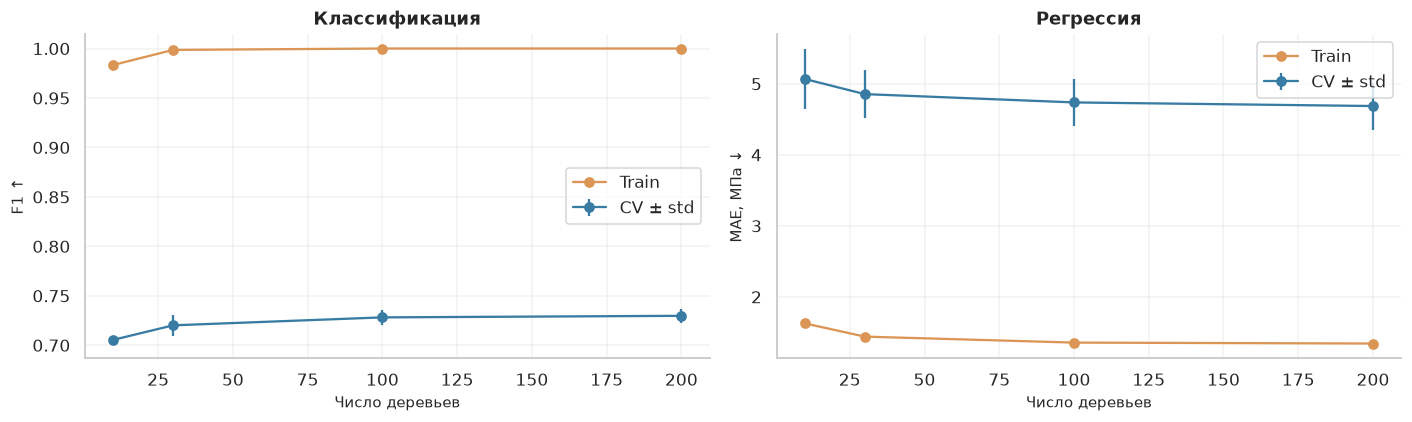

Задача,Деревьев,Среднее CV,Разброс CV,"Обучение, с"
Классификация,10,0.7054,0.0038,0.1064
Классификация,30,0.7201,0.0105,0.3226
Классификация,100,0.7281,0.0078,1.0636
Классификация,200,0.7297,0.0068,2.0881
Регрессия,10,-5.0671,0.4293,0.0136
Регрессия,30,-4.8545,0.3355,0.0400
Регрессия,100,-4.7373,0.3346,0.1307
Регрессия,200,-4.6864,0.3306,0.2595


Число деревьев для следующего этапа: {'classification': 200, 'regression': 200}


In [10]:
# Наращиваю лес внутри каждого фолда, не переиспользуя предобработку между фолдами.
size_records, chosen_sizes = [], {}
for task, t in tasks.items():
    for fold, (a, b) in enumerate(t["cv"]):
        preprocess = clone(base_models[task][:-1])
        Xt = preprocess.fit_transform(t["X_train"].iloc[a], t["y_train"].iloc[a])
        Xv = preprocess.transform(t["X_train"].iloc[b])
        params = baseline_params(task)
        params.update(warm_start=True, oob_score=False)
        forest = sklearn_model(task, **params)
        elapsed = 0.
        for size in [10, 30, 100, 200]:
            forest.set_params(n_estimators=size)
            started = perf_counter()
            forest.fit(Xt, t["y_train"].iloc[a])
            elapsed += perf_counter() - started
            score_fn = f1_score if task == "classification" else mean_absolute_error
            sign = 1 if task == "classification" else -1
            size_records.append(dict(task=task, fold=fold, n_estimators=size,
                cv_score=sign * score_fn(t["y_train"].iloc[b], forest.predict(Xv)),
                train_score=sign * score_fn(t["y_train"].iloc[a], forest.predict(Xt)), fit_seconds=elapsed))
    table = pd.DataFrame(size_records).query("task == @task")
    averages = table.groupby("n_estimators").cv_score.mean()
    chosen_sizes[task] = int(averages.idxmax())
size_results = pd.DataFrame(size_records)
size_results.to_csv(RESULTS / "n_estimators_cv.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, task in zip(axes, tasks):
    table = size_results.query("task == @task").groupby("n_estimators")
    sign = 1 if task == "classification" else -1
    ax.errorbar(table.cv_score.mean().index, sign * table.cv_score.mean(),
                yerr=table.cv_score.std(ddof=0), marker="o", label="CV ± std")
    ax.plot(table.train_score.mean().index, sign * table.train_score.mean(), marker="o", label="Train")
    ax.set(title=TASK_NAMES[task], xlabel="Число деревьев", ylabel="F1 ↑" if sign == 1 else "MAE, МПа ↓")
    ax.legend()
plt.tight_layout()
plt.show()
show_table(size_results.groupby(["task", "n_estimators"], as_index=False).agg(
    cv_mean=("cv_score", "mean"), cv_std=("cv_score", lambda s: s.std(ddof=0)),
    fit_seconds=("fit_seconds", "mean")))
print("Число деревьев для следующего этапа:", chosen_sizes)

### H5–H6: совместный подбор параметров и представления

При выбранном числе деревьев проверю полный набор комбинаций:
`raw/engineered`, глубина `12/None`, минимум в листе `1/5` для заявок и `1/3` для бетона,
`max_features='sqrt'/0.7` для заявок и `0.7/1.0` для бетона.
Для классификации добавлю `class_weight=None/'balanced_subsample'`.

Это **32 конфигурации классификации и 16 регрессии**, по три полных фолда, без уменьшения данных.
`balanced_subsample` пересчитывает веса классов отдельно в bootstrap каждого дерева;
оно не добавляет искусственные объекты, в отличие от oversampling.
Включу исходную конфигурацию как дополнительного кандидата: тогда выбранная конфигурация
не проиграет baseline по критерию отбора на этих же фолдах. Это не обещает выигрыша на test.

In [11]:
# Поиск выполняется исключительно по train, включая обучение преобразований внутри CV.
searches, selected = {}, {}
for task, t in tasks.items():
    grid = []
    for mode in ["raw", "engineered"]:
        pipe = make_pipeline(t["X_train"], task, mode)
        params = {"features": [pipe.named_steps["features"]],
                  "preprocess": [pipe.named_steps["preprocess"]],
                  "model__n_estimators": [chosen_sizes[task]],
                  "model__max_depth": [12, None],
                  "model__min_samples_leaf": [1, 5] if task == "classification" else [1, 3],
                  "model__max_features": ["sqrt", .7] if task == "classification" else [.7, 1.]}
        if task == "classification":
            params["model__class_weight"] = [None, "balanced_subsample"]
        grid.append(params)
    raw_pipe = base_models[task]
    baseline_grid = {"features": [raw_pipe.named_steps["features"]],
                     "preprocess": [raw_pipe.named_steps["preprocess"]]}
    baseline_grid.update({"model__" + key: [value] for key, value in baseline_params(task).items()})
    grid.append(baseline_grid)
    search = GridSearchCV(base_models[task], grid, cv=t["cv"], scoring=scoring[task],
                          n_jobs=1, error_score="raise", refit=False, return_train_score=True)
    print(f"Подбор: {task}", flush=True)
    search.fit(t["X_train"], t["y_train"])
    searches[task] = search
    best = clone(base_models[task]).set_params(**search.best_params_)
    estimator = best.named_steps["model"]
    keys = ["n_estimators", "max_depth", "min_samples_leaf", "max_features", "bootstrap", "max_samples", "oob_score"]
    if task == "classification": keys.append("class_weight")
    selected[task] = {"mode": best.named_steps["features"].mode,
                      "params": {key: estimator.get_params()[key] for key in keys},
                      "estimator": type(estimator).__name__, "cv_score": float(search.best_score_)}
    cv_rows = []
    for index, config in enumerate(search.cv_results_["params"]):
        candidate = clone(base_models[task]).set_params(**config)
        cv_rows.append({"mode": candidate.named_steps["features"].mode,
                       **{key: candidate.named_steps["model"].get_params()[key] for key in keys},
                       **{key: search.cv_results_[key][index] for key in
                          ["mean_test_score", "std_test_score", "rank_test_score", "mean_train_score",
                           "split0_test_score", "split1_test_score", "split2_test_score", "mean_fit_time"]}})
    table = pd.DataFrame(cv_rows)
    table.to_csv(RESULTS / f"cv_{task}.csv", index=False)
    show_table(table.sort_values("rank_test_score").head(10), TASK_NAMES[task] + ": лучшие CV-конфигурации")
    show_table(pd.DataFrame([{"mode": selected[task]["mode"], **selected[task]["params"],
                              "CV-score (F1 / −MAE)": selected[task]["cv_score"]}]), "Выбор по CV")
(RESULTS / "selected.json").write_text(json.dumps(selected, ensure_ascii=False, indent=2));

Подбор: classification


,Признаки,Деревьев,Предел глубины,Минимум в листе,Признаки в узле,Bootstrap,Размер bootstrap,oob_score,Веса классов,Среднее CV,Разброс CV,Место,Среднее train,split0_test_score,split1_test_score,split2_test_score,mean_fit_time
15,raw,200,—,5,0.7000,True,—,True,balanced_subsample,0.7614,0.0103,1,0.9330,0.7532,0.7759,0.7552,5.0327
31,engineered,200,—,5,0.7000,True,—,True,balanced_subsample,0.7604,0.0090,2,0.9380,0.7530,0.7731,0.7550,5.7593
6,raw,200,—,1,0.7000,True,—,True,—,0.7482,0.0096,3,1.0000,0.7348,0.7533,0.7566,5.3352
7,raw,200,—,5,0.7000,True,—,True,—,0.7448,0.0065,4,0.9177,0.7357,0.7504,0.7482,4.8093
22,engineered,200,—,1,0.7000,True,—,True,—,0.7433,0.0110,5,1.0000,0.7277,0.7523,0.7498,5.9477
23,engineered,200,—,5,0.7000,True,—,True,—,0.7420,0.0106,6,0.9227,0.7270,0.7488,0.7501,5.4978
13,raw,200,—,5,sqrt,True,—,True,balanced_subsample,0.7410,0.0099,7,0.8743,0.7345,0.7550,0.7337,2.3843
29,engineered,200,—,5,sqrt,True,—,True,balanced_subsample,0.7405,0.0107,8,0.8829,0.7328,0.7556,0.7330,2.5599
14,raw,200,—,1,0.7000,True,—,True,balanced_subsample,0.7382,0.0086,9,1.0000,0.7261,0.7434,0.7450,5.7833
10,raw,200,12.0000,1,0.7000,True,—,True,balanced_subsample,0.7379,0.0048,10,0.8293,0.7380,0.7437,0.7321,4.4857


Признаки,Деревьев,Предел глубины,Минимум в листе,Признаки в узле,Bootstrap,Размер bootstrap,oob_score,Веса классов,CV-score (F1 / −MAE)
raw,200,—,5,0.7000,True,—,True,balanced_subsample,0.7614


Подбор: regression


,Признаки,Деревьев,Предел глубины,Минимум в листе,Признаки в узле,Bootstrap,Размер bootstrap,oob_score,Среднее CV,Разброс CV,Место,Среднее train,split0_test_score,split1_test_score,split2_test_score,mean_fit_time
14,engineered,200,—,1,1.0000,True,—,True,-3.9971,0.2825,1,-1.3197,-4.3930,-3.8452,-3.7531,0.3229
10,engineered,200,12.0000,1,1.0000,True,—,True,-4.0150,0.2831,2,-1.3633,-4.4132,-3.8522,-3.7797,0.3244
12,engineered,200,—,1,0.7000,True,—,True,-4.0379,0.2762,3,-1.2868,-4.4264,-3.8782,-3.8089,0.2645
8,engineered,200,12.0000,1,0.7000,True,—,True,-4.0413,0.2460,4,-1.3512,-4.3808,-3.9376,-3.8055,0.2623
11,engineered,200,12.0000,3,1.0000,True,—,True,-4.2063,0.2654,5,-2.1949,-4.5817,-4.0180,-4.0193,0.2684
15,engineered,200,—,3,1.0000,True,—,True,-4.2064,0.2643,6,-2.1935,-4.5802,-4.0209,-4.0182,0.2634
13,engineered,200,—,3,0.7000,True,—,True,-4.2447,0.2660,7,-2.2827,-4.6157,-4.1123,-4.0059,0.2136
9,engineered,200,12.0000,3,0.7000,True,—,True,-4.2480,0.2645,8,-2.2861,-4.6172,-4.1157,-4.0112,0.2196
4,raw,200,—,1,0.7000,True,—,True,-4.6478,0.2917,9,-1.3492,-4.9582,-4.7278,-4.2573,0.2280
6,raw,200,—,1,1.0000,True,—,True,-4.6864,0.3306,10,-1.3419,-4.9941,-4.8376,-4.2277,0.2768


Признаки,Деревьев,Предел глубины,Минимум в листе,Признаки в узле,Bootstrap,Размер bootstrap,oob_score,CV-score (F1 / −MAE)
engineered,200,—,1,1.0000,True,—,True,-3.9971


### H7: отдельная проверка bootstrap

В дополнение к поиску сравню baseline с тремя контролями: все признаки в узле
(приближение к bagging деревьев), bootstrap размером 70% train и отсутствие bootstrap.
Остальные настройки остаются исходными. В исходной регрессии уже используются все признаки,
поэтому контроль `all_features` должен совпасть с baseline. Эти запуски поясняют механизм леса;
они не входят в финальный перебор H5–H6. Если диагностика показывает перспективное
направление, это основание для следующего исследования, а не изменения модели по test.

In [12]:
# Изолированные проверки разнообразия: одна модификация исходного леса за запуск.
bootstrap_records = []
for task, t in tasks.items():
    controls = {"baseline": {}, "all_features": {"max_features": 1.0},
                "bootstrap_70%": {"max_samples": .7},
                "no_bootstrap": {"bootstrap": False, "oob_score": False}}
    for label, changes in controls.items():
        if label == "baseline":
            values = next(h["folds"] for h in hypothesis_records if h["task"] == task and h["mode"] == "raw")
            scores = np.asarray(values)
        else:
            model = clone(base_models[task]).set_params(**{"model__" + k: v for k, v in changes.items()})
            scores = cross_val_score(model, t["X_train"], t["y_train"], cv=t["cv"],
                                     scoring=scoring[task], n_jobs=1, error_score="raise")
        bootstrap_records.append(dict(task=task, experiment=label, cv_mean=float(scores.mean()),
                                      cv_std=float(scores.std()), folds=scores.tolist()))
bootstrap_results = pd.DataFrame(bootstrap_records)
bootstrap_results.to_json(RESULTS / "bootstrap_cv.json", orient="records", indent=2)
show_table(bootstrap_results.drop(columns="folds"), "F1 / отрицательная MAE: больше — лучше")

Задача,experiment,Среднее CV,Разброс CV
Классификация,baseline,0.7281,0.0078
Классификация,all_features,0.7469,0.0093
Классификация,bootstrap_70%,0.7284,0.0056
Классификация,no_bootstrap,0.7343,0.0067
Регрессия,baseline,-4.7373,0.3346
Регрессия,all_features,-4.7373,0.3346
Регрессия,bootstrap_70%,-4.8395,0.3321
Регрессия,no_bootstrap,-5.6521,0.5716


### Итоги проверки гипотез

Для H1–H3 покажу парные изменения относительно raw или log.
Для H6 сравню средние результаты **сопоставимых конфигураций**, отличающихся только
весами классов. H5 рассматривается по срезам сетки на графиках ниже. Это описательная проверка на трёх общих фолдах, без утверждений
о статистической значимости. Выигрыш лучшего варианта среди множества кандидатов
может быть оптимистичным — отбор не равен независимой оценке качества.

In [13]:
# Дельты CV-score положительны при росте F1 или уменьшении MAE.
hypotheses = pd.DataFrame(hypothesis_records)
hypothesis_rows = []
for task in tasks:
    h = hypotheses.query("task == @task").set_index("mode")
    for label, left, right in [("H1 · scaling", "scaled", "raw"), ("H2 · log", "log", "raw"),
                                ("H3 · отношения после log", "engineered", "log")]:
        hypothesis_rows.append(dict(task=task, experiment=label, delta=h.loc[left, "cv_mean"]-h.loc[right, "cv_mean"]))
    table = pd.read_csv(RESULTS / f"cv_{task}.csv", keep_default_na=False).iloc[:-1]
    keys = ["mode", "n_estimators", "max_depth", "min_samples_leaf", "max_features"]
    if task == "classification":
        pair = table.pivot(index=keys, columns="class_weight", values="mean_test_score")
        hypothesis_rows.append(dict(task=task, experiment="H6 · balanced_subsample − обычные, среднее пар",
                                   delta=(pair["balanced_subsample"]-pair[""]).mean()))
    best_delta = selected[task]["cv_score"] - h.loc["raw", "cv_mean"]
    hypothesis_rows.append(dict(task=task, experiment="H4–H6 · выбранный вариант − baseline", delta=best_delta))
    for control in ["all_features", "bootstrap_70%", "no_bootstrap"]:
        row = bootstrap_results.query("task == @task and experiment == @control").iloc[0]
        hypothesis_rows.append(dict(task=task, experiment="H7 · "+control, delta=row.cv_mean-h.loc["raw", "cv_mean"]))
hypothesis_summary = pd.DataFrame(hypothesis_rows)
hypothesis_summary.to_csv(RESULTS / "hypothesis_summary.csv", index=False)
show_table(hypothesis_summary)
# Численные пояснения сохраняются рядом с таблицей.
for task in tasks:
    h = hypotheses.query("task == @task").set_index("mode")
    sign = 1 if task == "classification" else -1
    display(Markdown(f"**{TASK_NAMES[task]}:** raw CV = **{sign*h.loc['raw','cv_mean']:.5f}**, "
        f"scaled = **{sign*h.loc['scaled','cv_mean']:.5f}**, log = **{sign*h.loc['log','cv_mean']:.5f}**, "
        f"engineered = **{sign*h.loc['engineered','cv_mean']:.5f}**. "
        f"После подбора CV {'F1' if sign == 1 else 'MAE'} = **{sign*selected[task]['cv_score']:.5f}**. "
        "Отсутствие выигрыша также является результатом проверки гипотезы."))

Задача,experiment,Изменение
Классификация,H1 · scaling,-0.0003
Классификация,H2 · log,-0.0001
Классификация,H3 · отношения после log,-0.0038
Классификация,"H6 · balanced_subsample − обычные, среднее пар",0.0067
Классификация,H4–H6 · выбранный вариант − baseline,0.0333
Классификация,H7 · all_features,0.0188
Классификация,H7 · bootstrap_70%,0.0003
Классификация,H7 · no_bootstrap,0.0062
Регрессия,H1 · scaling,-0.0092
Регрессия,H2 · log,0.0069


**Классификация:** raw CV = **0.72813**, scaled = **0.72780**, log = **0.72799**, engineered = **0.72419**. После подбора CV F1 = **0.76143**. Отсутствие выигрыша также является результатом проверки гипотезы.

**Регрессия:** raw CV = **4.73732**, scaled = **4.74655**, log = **4.73044**, engineered = **4.02015**. После подбора CV MAE = **3.99708**. Отсутствие выигрыша также является результатом проверки гипотезы.

### Влияние параметров на CV

Покажу качество при разных размерах листа и долях признаков для выбранных представления,
глубины и весов. На графике остаются только сопоставимые варианты из полного поиска.
Разрыв train/CV помогает оценить переобучение; меньшая глубина и больший лист
могут одновременно снизить дисперсию и увеличить смещение.

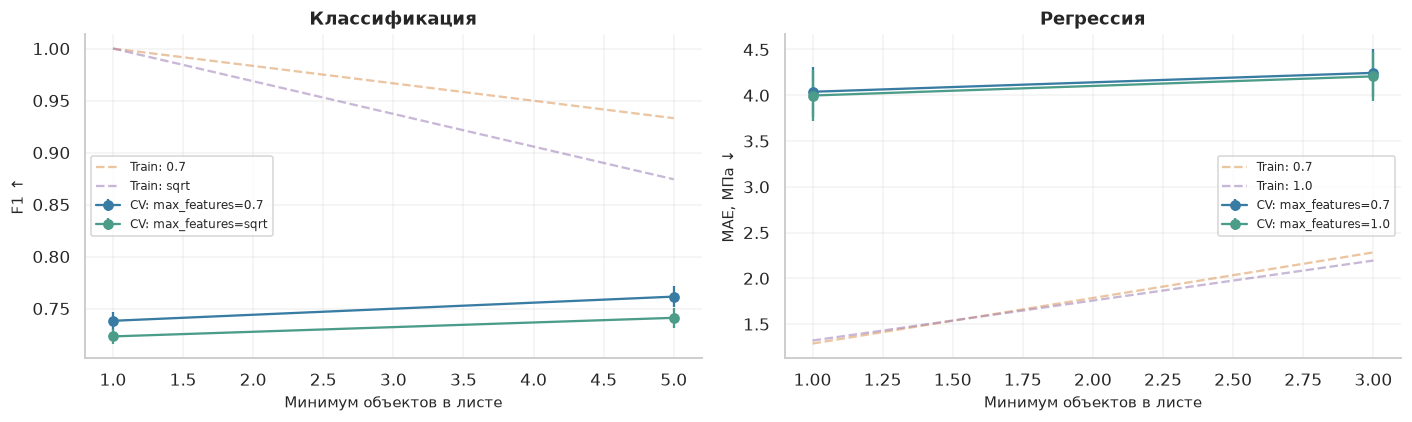

In [14]:
# Срез поиска удерживает все параметры, кроме min_samples_leaf и max_features.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, task in zip(axes, tasks):
    table = pd.read_csv(RESULTS / f"cv_{task}.csv", keep_default_na=False).iloc[:-1]
    config = selected[task]
    depth = "" if config["params"]["max_depth"] is None else str(config["params"]["max_depth"])
    subset = table[(table["mode"] == config["mode"]) & (table.max_depth.astype(str) == depth)]
    if task == "classification":
        subset = subset[subset.class_weight == (config["params"].get("class_weight") or "")]
    sign = 1 if task == "classification" else -1
    for feature_fraction, group in subset.groupby("max_features"):
        group = group.sort_values("min_samples_leaf")
        ax.errorbar(group.min_samples_leaf, sign*group.mean_test_score, yerr=group.std_test_score,
                    marker="o", label=f"CV: max_features={feature_fraction}")
        ax.plot(group.min_samples_leaf, sign*group.mean_train_score, linestyle="--", alpha=.55,
                label=f"Train: {feature_fraction}")
    ax.set(title=TASK_NAMES[task], xlabel="Минимум объектов в листе", ylabel="F1 ↑" if sign == 1 else "MAE, МПа ↓")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Улучшенный бейзлайн sklearn на test

Параметры и представления уже выбраны по CV. Обучу окончательные модели на полном train
и сравню с исходными. Улучшенный здесь означает результат процедуры улучшения по CV:
фактическое изменение на test может иметь любой знак.

In [15]:
# Конфигурации выбраны по CV; test используется только для отчёта.
for task in tasks:
    fit_evaluate(task, "sklearn_improved", make_pipeline(tasks[task]["X_train"], task, selected[task]["mode"],
                     sklearn_model(task, **selected[task]["params"])), selected[task]["mode"])
show_metrics(pd.DataFrame(records))
for task in tasks:
    metric = "f1" if task == "classification" else "mae"
    group = pd.DataFrame(records).query("task == @task").set_index("model")
    old, new = group.loc["sklearn_baseline", metric], group.loc["sklearn_improved", metric]
    display(Markdown(f"**{TASK_NAMES[task]}:** исходная {'F1' if task == 'classification' else 'MAE'} "
                     f"**{old:.5f}**, улучшенная **{new:.5f}**, изменение **{new-old:+.5f}**. "
                     f"Выигрыш на CV не гарантирует такой же выигрыш на test."))

Обучение classification: sklearn_improved


Обучение regression: sklearn_improved


Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP
Dummy,0.0000,0.0000,0.0000,0.5000,0.7778,0.5000,0.2222
sklearn · исходная,0.7406,0.8478,0.6575,0.8119,0.8977,0.9546,0.8764
sklearn · улучшенная,0.7757,0.7412,0.8135,0.8662,0.8954,0.9591,0.8885


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
Dummy,14.5233,18.1552,-0.0215
sklearn · исходная,4.6535,6.6475,0.8630
sklearn · улучшенная,3.9766,5.7124,0.8989


**Классификация:** исходная F1 **0.74064**, улучшенная **0.77569**, изменение **+0.03505**. Выигрыш на CV не гарантирует такой же выигрыш на test.

**Регрессия:** исходная MAE **4.65348**, улучшенная **3.97659**, изменение **-0.67688**. Выигрыш на CV не гарантирует такой же выигрыш на test.

## 4. Самостоятельная реализация случайного леса

Реализация состоит из двух частей: рандомизированное CART и ансамбль с bootstrap/OOB.
Поиск порогов, расчёт Gini/SSE, рост дерева, выбор признаков в узле, прогнозы,
веса классов и усреднение написаны на **NumPy**. Готовые деревья и леса sklearn
в своей реализации не используются. Из sklearn взяты интерфейс estimator,
валидация входов и функции отчётных метрик.

Логика CART развивает собственную реализацию №3. Для каждого признака сортирую значения,
перебираю пороги между различными соседями и через накопленные суммы вычисляю стоимость
всех разбиений. Лист хранит среднее цели или взвешенные доли классов.
Рост через стек не ограничен глубиной рекурсии Python.

В каждом узле случайно перемешиваю признаки и проверяю первые `max_features`.
Если среди них нет допустимого порога, продолжаю поиск до первого допустимого разбиения.
Разные деревья и bootstrap получают независимые воспроизводимые seed.

**Явное отличие реализации:** bootstrap материализуется повторяющимися строками,
поэтому `min_samples_leaf` и `min_samples_split` считают строки с повторами.
В sklearn кратности bootstrap передаются весами, а ограничения количества объектов
относятся к уникальным строкам узла. Это одна из причин несовпадения ответов.
Также отличаются генератор случайных чисел, последовательность выбора признаков
и разрешение равноценных разбиений. Совпадение целевой математики не требует
побитового совпадения отдельных ансамблей.

Простой пример отличия ограничений: bootstrap `[a, a, b, b]`, где `a` и `b` — два
различных объекта разных классов. При `min_samples_leaf=2` материализованный bootstrap
допускает два листа по две строки. В sklearn каждый такой лист содержал бы только
один уникальный объект, поэтому подобное разбиение запрещено. Это объясняет, почему
одинаковое число в параметрах не гарантирует одинаковую структуру деревьев.

### 4.1. Рандомизированное CART на NumPy

Ниже первая часть файла [src/random_forest.py](src/random_forest.py).
Числовые признаки приводятся к float32 на входе леса, стоимость считается в float64.
Для регрессии центрирую цель перед накоплением сумм, чтобы уменьшить потерю точности.
Важность признака равна нормированной сумме уменьшений нечистоты по его узлам.

In [16]:
# Собственный поиск разбиений и рост дерева; тот же код находится в src/random_forest.py.
"""Случайный лес на NumPy: bootstrap, случайные признаки в узлах и OOB.

Критерии, поиск порогов и рост CART перенесены из собственной реализации №3.
Готовые деревья и ансамбли sklearn не используются; sklearn нужен для API/валидации.
Bootstrap представлен повторяющимися строками: min_samples_* считают их с повторами.
"""

from numbers import Integral, Real
import warnings
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.utils.multiclass import check_classification_targets
from sklearn.metrics import accuracy_score, r2_score
from sklearn.utils.validation import check_is_fitted, validate_data


class _RandomizedTree(BaseEstimator):
    def __init__(self, max_depth=None, min_samples_split=2, min_samples_leaf=1,
                 min_impurity_decrease=0.0, max_features=None, random_state=42):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease
        self.max_features = max_features
        self.random_state = random_state

    def fit(self, X, y, classification, weights, n_classes=None):
        rng = np.random.default_rng(self.random_state)
        self._classification = classification
        if classification:
            target = y
            self.n_classes_ = n_classes
        else:
            # Центрирование уменьшает потерю точности при вычислении SSE.
            self.target_offset_ = float(np.mean(y))
            target = np.asarray(y, dtype=np.float64) - self.target_offset_
        self.nodes_ = []
        self.feature_importances_ = np.zeros(X.shape[1])
        self.max_depth_ = 0
        self.n_leaves_ = 0
        total_weight = weights.sum()
        # Стек вместо рекурсии позволяет строить и глубокие деревья.
        pending = [(np.arange(len(y)), 0, None, None)]
        while pending:
            indices, depth, parent, side = pending.pop()
            values, w = target[indices], weights[indices]
            mass = w.sum()
            if classification:
                histogram = np.bincount(values, weights=w, minlength=self.n_classes_)
                value = histogram / mass
                impurity = max(0.0, 1.0 - value @ value)
                parent_cost = mass * impurity
            else:
                mean = values.mean()
                value = mean + self.target_offset_
                parent_cost = float(np.sum((values - mean) ** 2))
                impurity = parent_cost / mass
            node = dict(feature=-1, threshold=np.nan, left=-1, right=-1, value=value,
                        n_samples=len(indices), impurity=impurity, depth=depth)
            node_id = len(self.nodes_)
            self.nodes_.append(node)
            if parent is not None:
                self.nodes_[parent][side] = node_id
            self.max_depth_ = max(self.max_depth_, depth)
            best = None
            best_cost = np.inf
            can_split = (len(indices) >= max(self.min_samples_split, 2 * self.min_samples_leaf)
                         and (self.max_depth is None or depth < self.max_depth)
                         and impurity > np.finfo(float).eps)
            if can_split:
                # Каждый узел получает новый случайный набор признаков.
                # Если первые m признаков не допускают порога, пробуем следующие.
                for attempt, feature in enumerate(rng.permutation(X.shape[1])):
                    if attempt >= self.max_features and best is not None:
                        break
                    order = np.argsort(X[indices, feature], kind="stable")
                    sorted_indices = indices[order]
                    x = X[sorted_indices, feature].astype(np.float64)
                    positions = np.arange(1, len(x))
                    # Почти равные float32-значения не образуют отдельный порог.
                    valid = ((x[1:] > x[:-1] + 1e-7)
                             & (positions >= self.min_samples_leaf)
                             & (len(x) - positions >= self.min_samples_leaf))
                    if not valid.any():
                        continue
                    ordered_target, ordered_w = target[sorted_indices], weights[sorted_indices]
                    if classification:
                        onehot = np.zeros((len(x), self.n_classes_))
                        onehot[np.arange(len(x)), ordered_target] = ordered_w
                        left_counts = np.cumsum(onehot, axis=0)[:-1]
                        right_counts = histogram - left_counts
                        left_mass = np.cumsum(ordered_w)[:-1]
                        right_mass = mass - left_mass
                        costs = (mass - (left_counts ** 2).sum(axis=1) / left_mass
                                 - (right_counts ** 2).sum(axis=1) / right_mass)
                    else:
                        cumulative = np.cumsum(ordered_target)[:-1]
                        cumulative2 = np.cumsum(ordered_target ** 2)[:-1]
                        total, total2 = ordered_target.sum(), np.sum(ordered_target ** 2)
                        costs = (cumulative2 - cumulative ** 2 / positions
                                 + total2 - cumulative2 - (total - cumulative) ** 2 / (len(x) - positions))
                    costs[~valid] = np.inf
                    cut = int(np.argmin(costs))
                    # При равенстве сохраняется первый признак и первый порог.
                    if costs[cut] < best_cost - 1e-12:
                        best_cost = float(costs[cut])
                        threshold = x[cut] / 2.0 + x[cut + 1] / 2.0
                        best = (feature, threshold, sorted_indices[:cut + 1], sorted_indices[cut + 1:])
            gain = 0.0 if best is None else max(0.0, parent_cost - best_cost)
            if best is None or gain / total_weight + 1e-15 < self.min_impurity_decrease:
                self.n_leaves_ += 1
                continue
            feature, threshold, left, right = best
            node.update(feature=feature, threshold=threshold)
            self.feature_importances_[feature] += gain
            pending.append((right, depth + 1, node_id, "right"))
            pending.append((left, depth + 1, node_id, "left"))
        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        self.node_count_ = len(self.nodes_)
        return self

    def _values(self, X):
        shape = (len(X), self.n_classes_) if self._classification else (len(X),)
        result = np.empty(shape)
        pending = [(0, np.arange(len(X)))]
        while pending:
            node_id, rows = pending.pop()
            if not len(rows):
                continue
            node = self.nodes_[node_id]
            if node["feature"] < 0:
                result[rows] = node["value"]
            else:
                goes_left = X[rows, node["feature"]] <= node["threshold"]
                pending.append((node["left"], rows[goes_left]))
                pending.append((node["right"], rows[~goes_left]))
        return result

    def get_depth(self):
        check_is_fitted(self, "nodes_")
        return self.max_depth_

    def get_n_leaves(self):
        check_is_fitted(self, "nodes_")
        return self.n_leaves_

### 4.2. Bootstrap, объединение деревьев и OOB

Вторая часть того же файла реализует estimator API, усреднение вероятностей/значений,
нормировку важностей и OOB. Для отсутствующих в bootstrap классов сохраняются нулевые
вероятности в соответствующих столбцах. OOB-строки без единого прогноза получают NaN;
их доля явно учитывается, а не заменяется искусственным нулём.

Стандартный `oob_score_` — **accuracy** для классификации и **R²** для регрессии.
Основные F1/MAE посчитаю отдельно. Поддерживаются одноцелевая регрессия, бинарная
и многоклассовая классификация; sparse-входы и NaN предварительно обрабатывает Pipeline.

In [17]:
# Собственная логика ансамбля; готовые деревья sklearn здесь не вызываются.
class _Forest(BaseEstimator):
    def __init__(self, n_estimators=100, max_depth=None, min_samples_split=2,
                 min_samples_leaf=1, max_features=1.0, bootstrap=True,
                 max_samples=None, oob_score=False, random_state=None):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.bootstrap = bootstrap
        self.max_samples = max_samples
        self.oob_score = oob_score
        self.random_state = random_state

    def _validate_parameters(self, n_samples, n_features):
        for name, lower in [("n_estimators", 1), ("max_depth", 1),
                            ("min_samples_split", 2), ("min_samples_leaf", 1)]:
            value = getattr(self, name)
            if name == "max_depth" and value is None:
                continue
            if isinstance(value, bool) or not isinstance(value, Integral) or value < lower:
                raise ValueError(f"{name} должен быть целым >= {lower}")
        if not isinstance(self.bootstrap, bool) or not isinstance(self.oob_score, bool):
            raise ValueError("bootstrap и oob_score должны быть bool")
        if not self.bootstrap and (self.oob_score or self.max_samples is not None):
            raise ValueError("OOB и max_samples требуют bootstrap=True")
        if self.random_state is not None and (isinstance(self.random_state, bool)
                or not isinstance(self.random_state, Integral) or self.random_state < 0):
            raise ValueError("random_state должен быть неотрицательным целым или None")
        m = self.max_features
        if m is None:
            self.max_features_ = n_features
        elif isinstance(m, str) and m in ("sqrt", "log2"):
            self.max_features_ = max(1, int(np.sqrt(n_features) if m == "sqrt" else np.log2(n_features)))
        elif not isinstance(m, bool) and isinstance(m, Integral) and 1 <= m <= n_features:
            self.max_features_ = int(m)
        elif not isinstance(m, bool) and isinstance(m, Real) and 0 < m <= 1:
            self.max_features_ = max(1, int(m * n_features))
        else:
            raise ValueError("Некорректное max_features")
        m = self.max_samples
        if m is None:
            self.n_samples_bootstrap_ = n_samples
        elif not isinstance(m, bool) and isinstance(m, Integral) and 1 <= m <= n_samples:
            self.n_samples_bootstrap_ = int(m)
        elif not isinstance(m, bool) and isinstance(m, Real) and 0 < m <= 1:
            self.n_samples_bootstrap_ = max(1, round(m * n_samples))
        else:
            raise ValueError("Некорректное max_samples")

    def _fit(self, X, y, classification):
        X, y = validate_data(self, X, y, dtype=np.float32, y_numeric=not classification)
        if y.ndim != 1:
            raise ValueError("Поддерживается одна целевая переменная")
        self._validate_parameters(len(X), X.shape[1])
        self._classification = classification
        if classification:
            check_classification_targets(y)
            if self.class_weight not in (None, "balanced", "balanced_subsample"):
                raise ValueError("class_weight: None, balanced или balanced_subsample")
            self.classes_, target = np.unique(y, return_inverse=True)
            self.n_classes_ = len(self.classes_)
            global_counts = np.bincount(target, minlength=self.n_classes_)
        else:
            target = np.asarray(y, dtype=float)
        # Удаляем старые OOB-атрибуты при повторном fit с oob_score=False.
        for name in ["oob_score_", "oob_prediction_", "oob_decision_function_",
                     "oob_counts_", "oob_coverage_"]:
            self.__dict__.pop(name, None)
        rng = np.random.default_rng(self.random_state)
        self.estimators_, self.estimators_samples_, self.tree_seeds_ = [], [], []
        for _ in range(self.n_estimators):
            seed = int(rng.integers(0, np.iinfo(np.int32).max))
            sample_rng = np.random.default_rng(seed)
            indices = (sample_rng.integers(0, len(X), size=self.n_samples_bootstrap_)
                       if self.bootstrap else np.arange(len(X)))
            weights = np.ones(len(indices))
            if classification and self.class_weight is not None:
                counts = (np.bincount(target[indices], minlength=self.n_classes_)
                          if self.class_weight == "balanced_subsample" else global_counts)
                total = len(indices) if self.class_weight == "balanced_subsample" else len(X)
                # Отсутствующий в bootstrap класс не даёт деления на ноль.
                weights = total / (self.n_classes_ * counts[target[indices]])
            tree = _RandomizedTree(self.max_depth, self.min_samples_split,
                                   self.min_samples_leaf, max_features=self.max_features_,
                                   random_state=seed)
            tree.fit(X[indices], target[indices], classification, weights,
                     self.n_classes_ if classification else None)
            self.estimators_.append(tree)
            self.estimators_samples_.append(indices)
            self.tree_seeds_.append(seed)
        importance = np.mean([tree.feature_importances_ for tree in self.estimators_], axis=0)
        self.feature_importances_ = importance / importance.sum() if importance.sum() else importance
        if self.oob_score:
            self._compute_oob(X, target)
        return self

    def _compute_oob(self, X, y):
        shape = (len(X), self.n_classes_) if self._classification else (len(X),)
        sums = np.zeros(shape)
        self.oob_counts_ = np.zeros(len(X), dtype=int)
        for tree, samples in zip(self.estimators_, self.estimators_samples_):
            rows = np.flatnonzero(np.bincount(samples, minlength=len(X)) == 0)
            if len(rows):
                sums[rows] += tree._values(X[rows])
                self.oob_counts_[rows] += 1
        valid = self.oob_counts_ > 0
        self.oob_coverage_ = float(valid.mean())
        result = np.full(shape, np.nan)
        divisor = self.oob_counts_[valid, None] if self._classification else self.oob_counts_[valid]
        result[valid] = sums[valid] / divisor
        if not valid.all():
            warnings.warn("Некоторые строки не имеют OOB-деревьев: прогноз для них NaN", UserWarning)
        if self._classification:
            self.oob_decision_function_ = result
            self.oob_score_ = accuracy_score(y[valid], result[valid].argmax(axis=1)) if valid.any() else np.nan
        else:
            self.oob_prediction_ = result
            self.oob_score_ = r2_score(y[valid], result[valid]) if valid.sum() >= 2 else np.nan

    def _predict_values(self, X):
        check_is_fitted(self, "estimators_")
        X = validate_data(self, X, reset=False, dtype=np.float32)
        # Суммирование без хранения тензора n_trees × n_samples × n_classes.
        result = self.estimators_[0]._values(X).copy()
        for tree in self.estimators_[1:]:
            result += tree._values(X)
        return result / len(self.estimators_)


class NumpyRandomForestClassifier(ClassifierMixin, _Forest):
    """Лес Gini; усредняются вероятности листьев, при равенстве — первый класс."""

    def __init__(self, n_estimators=100, max_depth=None, min_samples_split=2,
                 min_samples_leaf=1, max_features="sqrt", bootstrap=True,
                 max_samples=None, oob_score=False, random_state=None, class_weight=None):
        super().__init__(n_estimators, max_depth, min_samples_split, min_samples_leaf,
                         max_features, bootstrap, max_samples, oob_score, random_state)
        self.class_weight = class_weight

    def fit(self, X, y):
        return self._fit(X, y, classification=True)

    def predict_proba(self, X):
        return self._predict_values(X)

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return self.classes_[probabilities.argmax(axis=1)]


class NumpyRandomForestRegressor(RegressorMixin, _Forest):
    """Лес squared_error; ответ — среднее прогнозов CART."""

    def fit(self, X, y):
        return self._fit(X, y, classification=False)

    def predict(self, X):
        return self._predict_values(X)

### Проверка алгоритма на понятных примерах

Проверю XOR с константными столбцами: признак должен переизбираться в каждом узле,
а константные кандидаты не должны останавливать дерево. На регрессии проверю,
что ответ равен среднему деревьев. Полные тесты дополнительно реконструируют OOB
только по невыбранным строкам, проверяют веса, редкие классы, clone, ограничения и seed.

In [18]:
# Небольшие проверки можно воспроизвести вручную; они не используют данные test.
X_toy = np.array([[0,0,1], [0,1,1], [1,0,1], [1,1,1]], dtype=float)
y_toy = np.array([0,1,1,0])
toy = NumpyRandomForestClassifier(n_estimators=3, max_features=1, bootstrap=False,
                                   max_depth=2, random_state=42).fit(X_toy, y_toy)
np.testing.assert_array_equal(toy.predict(X_toy), y_toy)
np.testing.assert_allclose(toy.predict_proba(X_toy).sum(axis=1), 1)
reg_toy = NumpyRandomForestRegressor(n_estimators=5, max_depth=2, random_state=42).fit(
    np.arange(12)[:, None], np.arange(12, dtype=float)**2)
query = np.array([[1.5], [7.5]], dtype=np.float32)
np.testing.assert_allclose(reg_toy.predict(query), np.mean([tree._values(query) for tree in reg_toy.estimators_], axis=0))
from lab_4.src.random_forest import NumpyRandomForestClassifier as FileClassifier
from lab_4.src.random_forest import NumpyRandomForestRegressor as FileRegressor
np.testing.assert_allclose(toy.predict_proba(X_toy), FileClassifier(**toy.get_params()).fit(X_toy,y_toy).predict_proba(X_toy))
print("Проверки XOR, нормировки вероятностей, усреднения и версии из src пройдены.")

Проверки XOR, нормировки вероятностей, усреднения и версии из src пройдены.


### 4.3. Исходные собственные модели

Для прямого сравнения использую исходные 100 деревьев, те же представления,
критерии, глубину, bootstrap и ограничения листьев, что у sklearn.
Не уменьшаю train для ускорения своей реализации. Сравню метрики и время полного Pipeline.

In [19]:
# Исходные параметры совпадают по смыслу с исходным sklearn; seed фиксирован.
for task, t in tasks.items():
    cls = NumpyRandomForestClassifier if task == "classification" else NumpyRandomForestRegressor
    estimator = cls(random_state=SEED, **baseline_params(task))
    fit_evaluate(task, "custom_baseline", make_pipeline(t["X_train"], task, "raw", estimator), "raw")
show_metrics(pd.DataFrame(records).query("model in ['sklearn_baseline', 'custom_baseline']"))
for task in tasks:
    metric = "f1" if task == "classification" else "mae"
    m = pd.DataFrame(records).query("task == @task").set_index("model")
    display(Markdown(f"**{TASK_NAMES[task]}:** своя исходная минус sklearn по "
                     f"{'F1' if metric == 'f1' else 'MAE, МПа'} = "
                     f"**{m.loc['custom_baseline',metric]-m.loc['sklearn_baseline',metric]:+.5f}**. "
                     "Это сравнение качества двух реализаций, а не требование одинаковых прогнозов."))

Обучение classification: custom_baseline


Обучение regression: custom_baseline


Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP
sklearn · исходная,0.7406,0.8478,0.6575,0.8119,0.8977,0.9546,0.8764
своя · исходная,0.7438,0.8453,0.6640,0.8146,0.8983,0.9543,0.8758


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
sklearn · исходная,4.6535,6.6475,0.8630
своя · исходная,4.5787,6.6253,0.8640


**Классификация:** своя исходная минус sklearn по F1 = **+0.00313**. Это сравнение качества двух реализаций, а не требование одинаковых прогнозов.

**Регрессия:** своя исходная минус sklearn по MAE, МПа = **-0.07473**. Это сравнение качества двух реализаций, а не требование одинаковых прогнозов.

### 4.4. Перенос техник улучшенного бейзлайна

Перенесу выбранные на sklearn-CV представление, число деревьев, глубину, размер листа,
долю признаков и веса классов в свою реализацию **без повторного подбора**.
Так проверяется переносимость техники улучшения. Собственная реализация могла бы
иметь другой оптимум, но искать его по test было бы неправильно.

In [20]:
# Один и тот же словарь настроек применяется к обеим реализациям.
for task, t in tasks.items():
    cls = NumpyRandomForestClassifier if task == "classification" else NumpyRandomForestRegressor
    config = selected[task]
    estimator = cls(random_state=SEED, **config["params"])
    fit_evaluate(task, "custom_improved", make_pipeline(t["X_train"], task, config["mode"], estimator), config["mode"])
metrics = pd.DataFrame(records)
metrics.to_csv(RESULTS / "metrics.csv", index=False)
pd.DataFrame(complexity).to_csv(RESULTS / "complexity.csv", index=False)
show_metrics(metrics)

Обучение classification: custom_improved


Обучение regression: custom_improved


Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP
Dummy,0.0000,0.0000,0.0000,0.5000,0.7778,0.5000,0.2222
sklearn · исходная,0.7406,0.8478,0.6575,0.8119,0.8977,0.9546,0.8764
sklearn · улучшенная,0.7757,0.7412,0.8135,0.8662,0.8954,0.9591,0.8885
своя · исходная,0.7438,0.8453,0.6640,0.8146,0.8983,0.9543,0.8758
своя · улучшенная,0.7764,0.7657,0.7875,0.8593,0.8992,0.9596,0.8898


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
Dummy,14.5233,18.1552,-0.0215
sklearn · исходная,4.6535,6.6475,0.8630
sklearn · улучшенная,3.9766,5.7124,0.8989
своя · исходная,4.5787,6.6253,0.8640
своя · улучшенная,3.9479,5.7313,0.8982


### Совпадение прогнозов и сложность ансамблей

Измерю долю различных классов и абсолютные разности вероятностей/прогнозов до и после
улучшений. На одних метриках близкие значения могут скрывать разные ошибки на отдельных
объектах. Средняя глубина и число узлов помогают объяснить затраты своей реализации.

In [21]:
# Измеряю фактическое расхождение; не подгоняю свою реализацию под ответы test.
agreements, agreement_rows = {}, []
for task in tasks:
    agreements[task] = {}
    for stage in ["baseline", "improved"]:
        own, own_prob = predictions[task, "custom_" + stage]
        ref, ref_prob = predictions[task, "sklearn_" + stage]
        if task == "classification":
            difference = {"Доля разных классов": float(np.mean(own != ref)),
                          "Средняя разность вероятностей": float(np.mean(np.abs(own_prob - ref_prob))),
                          "Максимальная разность вероятностей": float(np.max(np.abs(own_prob - ref_prob)))}
        else:
            difference = {"Средняя разность прогнозов, МПа": float(np.mean(np.abs(own - ref))),
                          "Максимальная разность прогнозов, МПа": float(np.max(np.abs(own - ref)))}
        agreements[task][stage] = difference
        agreement_rows.append({"task": task, "stage": stage, **difference})
(RESULTS / "agreement.json").write_text(json.dumps(agreements, ensure_ascii=False, indent=2))
show_table(pd.DataFrame(agreement_rows))
show_table(pd.DataFrame(complexity), "Сложность и качество train (F1 / MAE)")

Задача,Вариант,Доля разных классов,Средняя разность вероятностей,Максимальная разность вероятностей,"Средняя разность прогнозов, МПа","Максимальная разность прогнозов, МПа"
Классификация,baseline,0.0240,0.0201,0.2200,—,—
Классификация,improved,0.0204,0.0139,0.1964,—,—
Регрессия,baseline,—,—,—,0.6847,2.8193
Регрессия,improved,—,—,—,0.4095,1.5509


Задача,Модель,Деревьев,Средняя глубина,Всего узлов,Качество train
Классификация,sklearn · исходная,100,31.8900,657032,1.0000
Регрессия,sklearn · исходная,100,18.2800,99528,1.2398
Классификация,sklearn · улучшенная,200,27.2250,450550,0.9348
Регрессия,sklearn · улучшенная,200,18.2900,199362,1.1955
Классификация,своя · исходная,100,31.9300,660600,1.0000
Регрессия,своя · исходная,100,18.1300,98740,1.2803
Классификация,своя · улучшенная,200,28.8300,613724,0.9665
Регрессия,своя · улучшенная,200,18.3100,197864,1.2204


## 5. Дополнительный анализ и сравнение результатов

### OOB: покрытие и качество

Покажу основной F1/MAE на OOB и стандартный `oob_score_`. В знаменатель метрик входят
только строки с хотя бы одним OOB-деревом. Приведу число OOB-голосов и долю уникальных
строк bootstrap, чтобы проверить механизм ресэмплинга на полных данных.
Для бетона OOB относится к исключению строк и может быть оптимистичнее оценки новых рецептур.

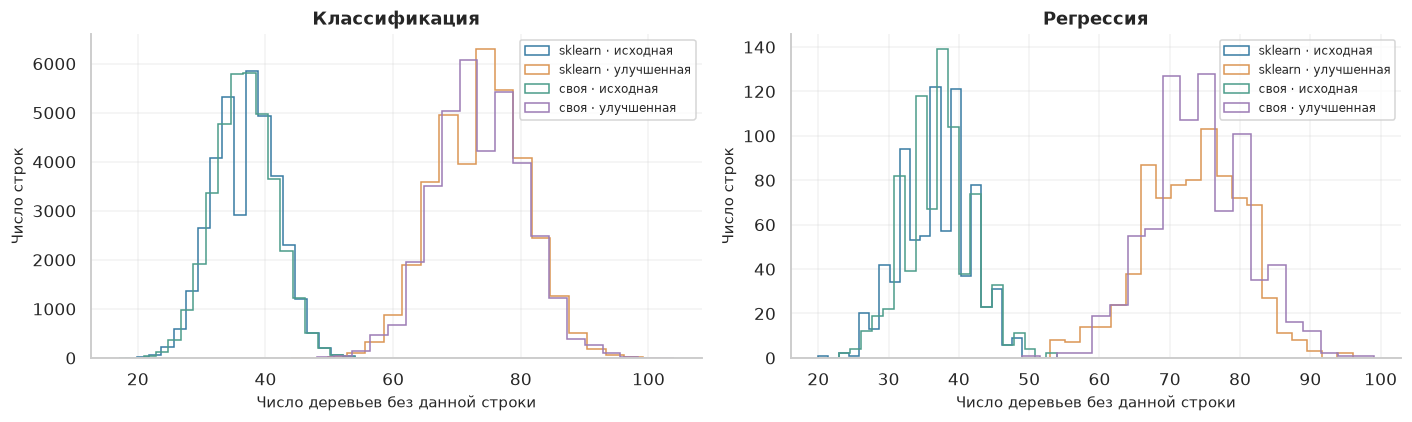

Задача,Модель,Покрытие OOB,OOB F1 / MAE,standard_oob_score,mean_oob_trees
Классификация,sklearn · исходная,1.0000,0.7316,0.8927,36.7999
Классификация,sklearn · улучшенная,1.0000,0.7705,0.8929,73.5977
Классификация,своя · исходная,1.0000,0.7319,0.8926,36.7666
Классификация,своя · улучшенная,1.0000,0.7700,0.8966,73.5662
Регрессия,sklearn · исходная,1.0000,3.2937,0.9116,36.8536
Регрессия,sklearn · улучшенная,1.0000,3.1945,0.9158,73.3980
Регрессия,своя · исходная,1.0000,3.3787,0.9113,37.1777
Регрессия,своя · улучшенная,1.0000,3.2327,0.9150,74.0951


Задача,Модель,unique_fraction,expected_unique_fraction
Классификация,sklearn · исходная,0.6320,0.6321
Классификация,sklearn · улучшенная,0.6320,0.6321
Классификация,своя · исходная,0.6323,0.6321
Классификация,своя · улучшенная,0.6322,0.6321
Регрессия,sklearn · исходная,0.6315,0.6324
Регрессия,sklearn · улучшенная,0.6330,0.6324
Регрессия,своя · исходная,0.6282,0.6324
Регрессия,своя · улучшенная,0.6295,0.6324


In [22]:
# OOB-прогнозы берутся из обучения; test не участвует в этой диагностике.
oob_rows, bootstrap_audit = [], []
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, task in zip(axes, tasks):
    t = tasks[task]
    for name in ["sklearn_baseline", "sklearn_improved", "custom_baseline", "custom_improved"]:
        forest = fitted[task, name].named_steps["model"]
        counts = np.zeros(len(t["X_train"]), dtype=int)
        unique_fractions = []
        for samples in forest.estimators_samples_:
            counts += np.bincount(samples, minlength=len(counts)) == 0
            unique_fractions.append(len(np.unique(samples))/len(counts))
        valid = counts > 0
        if task == "classification":
            p = forest.oob_decision_function_[valid]
            value = f1_score(t["y_train"].to_numpy()[valid], forest.classes_[p.argmax(axis=1)])
        else:
            value = mean_absolute_error(t["y_train"].to_numpy()[valid], forest.oob_prediction_[valid])
        oob_rows.append(dict(task=task, model=name, oob_coverage=float(valid.mean()),
            oob_primary=value, standard_oob_score=forest.oob_score_, mean_oob_trees=float(counts.mean())))
        bootstrap_audit.append(dict(task=task, model=name, unique_fraction=float(np.mean(unique_fractions)),
            expected_unique_fraction=1-(1-1/len(counts))**len(forest.estimators_samples_[0])))
        ax.hist(counts, bins=20, histtype="step", label=MODEL_NAMES[name])
        if hasattr(forest, "oob_counts_"):
            np.testing.assert_array_equal(forest.oob_counts_, counts)
    ax.set(title=TASK_NAMES[task], xlabel="Число деревьев без данной строки", ylabel="Число строк")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
oob_results = pd.DataFrame(oob_rows)
oob_results.to_csv(RESULTS / "oob.csv", index=False)
pd.DataFrame(bootstrap_audit).to_csv(RESULTS / "bootstrap_audit.csv", index=False)
show_table(oob_results, "Основной OOB F1 / MAE и стандартные accuracy / R²")
show_table(pd.DataFrame(bootstrap_audit), "Фактическая и ожидаемая доля уникальных строк bootstrap")

### Устойчивость к random_state

При уже выбранной конфигурации повторю CV для seed 7, 21 и 42.
Рецептуры и строки фолдов остаются теми же: меняется только случайность леса.
Не выбираю лучший seed по результату. Это описывает чувствительность к генератору,
но не неопределённость от выбора нового train/test. Для seed 42 использую уже посчитанные CV-оценки.

In [23]:
# Три seed проверяются по train-CV, без дополнительных обращений к test.
seed_records = []
for task, t in tasks.items():
    for seed in [7, 21, 42]:
        if seed == SEED:
            search = searches[task]
            scores = np.array([search.cv_results_[f"split{i}_test_score"][search.best_index_] for i in range(3)])
        else:
            pipe = make_pipeline(t["X_train"], task, selected[task]["mode"], sklearn_model(task, **selected[task]["params"]))
            pipe.set_params(model__random_state=seed)
            scores = cross_val_score(pipe, t["X_train"], t["y_train"], cv=t["cv"], scoring=scoring[task], n_jobs=1, error_score="raise")
        seed_records.append(dict(task=task, seed=seed, cv_mean=float(scores.mean()), cv_std=float(scores.std()), folds=scores.tolist()))
seed_results = pd.DataFrame(seed_records)
seed_results.to_json(RESULTS / "seed_cv.json", orient="records", indent=2)
show_table(seed_results.drop(columns="folds"), "Чувствительность выбранной модели к seed (F1 / −MAE)")
for task in tasks:
    values = seed_results.query("task == @task").cv_mean
    display(Markdown(f"**{TASK_NAMES[task]}:** диапазон среднего CV-score по seed "
                     f"**[{values.min():.5f}; {values.max():.5f}]**, размах **{values.max()-values.min():.5f}**."))

Задача,Seed,Среднее CV,Разброс CV
Классификация,7,0.7611,0.0087
Классификация,21,0.7612,0.0075
Классификация,42,0.7614,0.0103
Регрессия,7,-3.9785,0.2786
Регрессия,21,-4.0134,0.3030
Регрессия,42,-3.9971,0.2825


**Классификация:** диапазон среднего CV-score по seed **[0.76106; 0.76143]**, размах **0.00037**.

**Регрессия:** диапазон среднего CV-score по seed **[-4.01341; -3.97846]**, размах **0.03495**.

### Ошибки улучшенного sklearn

Покажу матрицу ошибок, ROC и precision–recall для заявок; затем прогнозы прочности,
остатки и абсолютные ошибки на новых рецептурах. Это анализ уже выбранной модели:
по этим графикам не меняю параметры или порог. Прямая на графике «факт–прогноз»
соответствует идеальному ответу, остаток — факт минус прогноз.

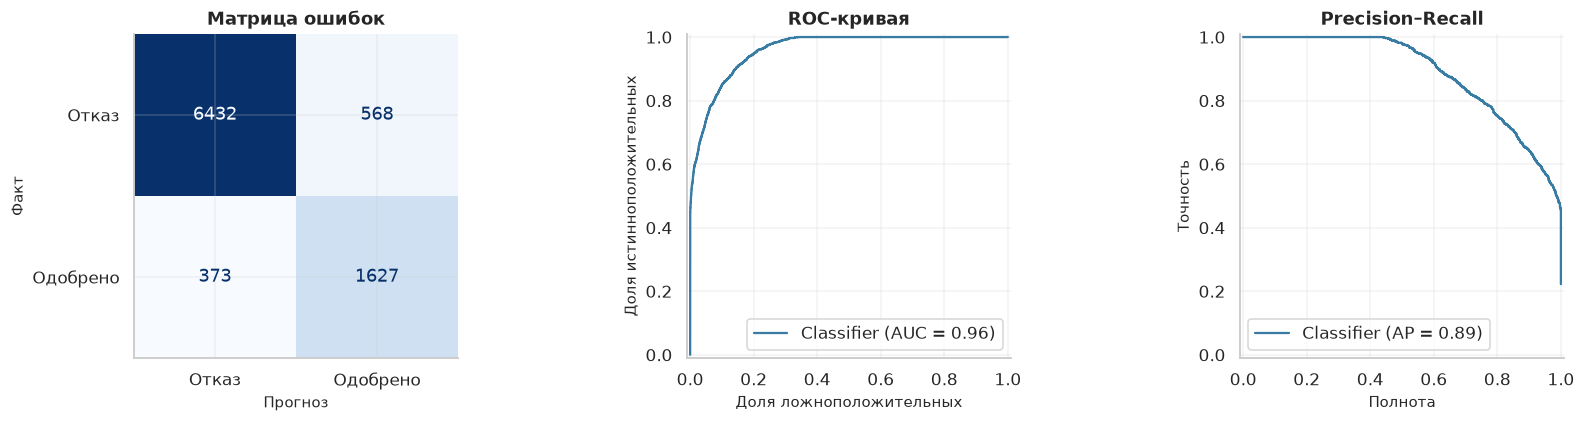

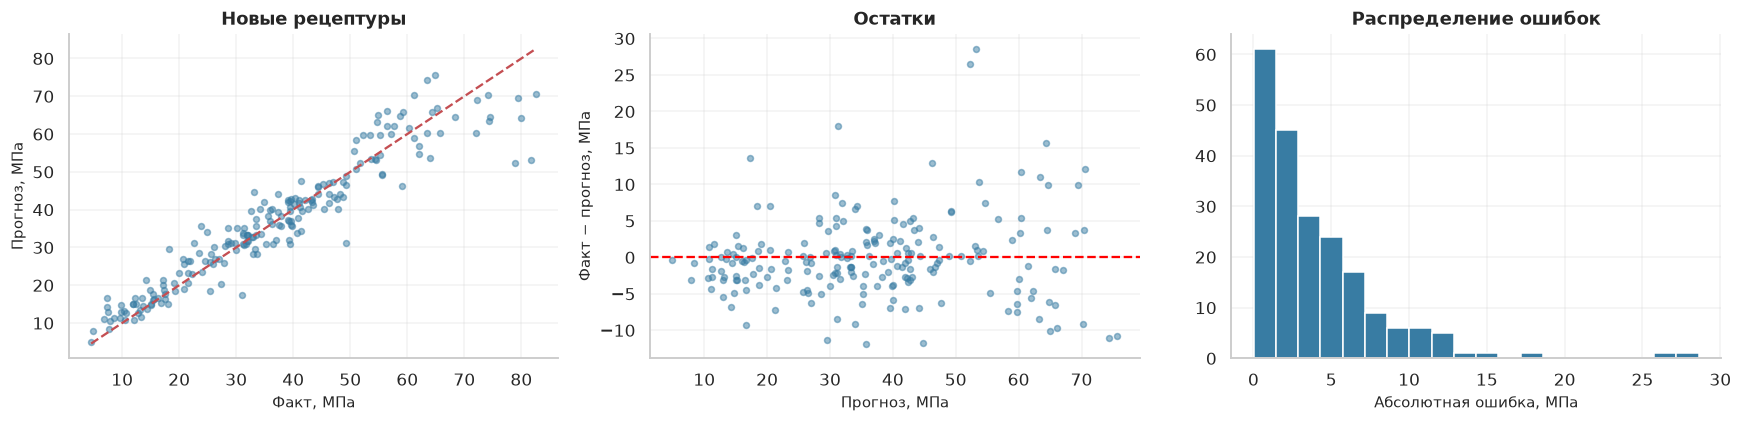

In [24]:
# Визуальная диагностика после выбора конфигурации; test не участвует в дальнейшем подборе.
y_c = tasks["classification"]["y_test"]
pred_c, prob_c = predictions["classification", "sklearn_improved"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(y_c, pred_c, ax=axes[0], colorbar=False, cmap="Blues", display_labels=["Отказ", "Одобрено"])
RocCurveDisplay.from_predictions(y_c, prob_c, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_c, prob_c, ax=axes[2])
axes[0].set(title="Матрица ошибок", xlabel="Прогноз", ylabel="Факт")
axes[1].set(title="ROC-кривая", xlabel="Доля ложноположительных", ylabel="Доля истинноположительных")
axes[2].set(title="Precision–Recall", xlabel="Полнота", ylabel="Точность")
plt.tight_layout()
plt.show()
y_r = tasks["regression"]["y_test"].to_numpy()
pred_r = predictions["regression", "sklearn_improved"][0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(y_r, pred_r, alpha=.5, s=15)
axes[0].plot([y_r.min(), y_r.max()], [y_r.min(), y_r.max()], "r--")
axes[0].set(xlabel="Факт, МПа", ylabel="Прогноз, МПа", title="Новые рецептуры")
axes[1].scatter(pred_r, y_r - pred_r, alpha=.5, s=15)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Прогноз, МПа", ylabel="Факт − прогноз, МПа", title="Остатки")
axes[2].hist(np.abs(y_r - pred_r), bins=20)
axes[2].set(xlabel="Абсолютная ошибка, МПа", title="Распределение ошибок")
plt.tight_layout()
plt.show()

### Какие ошибки остаются

Посчитаю FP/FN, среднюю ошибку по классам и MAE по диапазонам прочности.
Для небольших подгрупп оценка нестабильна; значения служат диагностикой.
Реальные одобрения в наборе не являются метками будущего дефолта клиента.

In [25]:
# Описываю ошибки на test после завершения отбора; таблицы не используются для настройки.
fp = int(np.sum((np.asarray(y_c)==0) & (pred_c==1)))
fn = int(np.sum((np.asarray(y_c)==1) & (pred_c==0)))
display(Markdown(f"**Классификация:** ошибочные одобрения FP = **{fp}**, "
                 f"пропущенные одобрения FN = **{fn}**. Изменение порога смещает этот баланс; "
                 "в работе он остаётся равным 0,5."))
error_table = pd.DataFrame({"truth":y_r, "prediction":pred_r, "absolute_error":np.abs(y_r-pred_r)})
error_table["Прочность"] = pd.cut(error_table.truth, [-np.inf,20,40,60,np.inf],
                                labels=["<20", "20–40", "40–60", ">60"])
show_table(error_table.groupby("Прочность", observed=True).agg(count=("truth","size"),
    mae=("absolute_error","mean"), mean_residual=("truth", lambda s: np.mean(s-error_table.loc[s.index,"prediction"]))))
display(Markdown(f"**Регрессия:** медиана абсолютной ошибки **{np.median(np.abs(y_r-pred_r)):.3f} МПа**, "
                 f"90-й процентиль **{np.quantile(np.abs(y_r-pred_r),.9):.3f} МПа**, "
                 f"максимум **{np.max(np.abs(y_r-pred_r)):.3f} МПа**."))

**Классификация:** ошибочные одобрения FP = **568**, пропущенные одобрения FN = **373**. Изменение порога смещает этот баланс; в работе он остаётся равным 0,5.

,Количество,"MAE, МПа ↓",mean_residual
Прочность,,,
<20,45,2.6210,-2.1340
20–40,82,3.3515,-0.8982
40–60,56,3.9397,0.2054
>60,23,8.9471,5.8525


**Регрессия:** медиана абсолютной ошибки **2.758 МПа**, 90-й процентиль **9.136 МПа**, максимум **28.609 МПа**.

### Важности признаков: MDI и permutation importance

MDI — доля уменьшения нечистоты узлов по признаку, усреднённая по деревьям.
Она смещается в пользу признаков с большим числом возможных порогов и не доказывает причинность.
Покажу агрегирование one-hot-столбцов до исходного признака; созданные отношения оставлю отдельно.

Permutation importance оценю на **validation первого CV-фолда**, обучив отдельный выбранный
Pipeline только на train этого фолда. Перемешиваю исходные столбцы, затем пересчитываются
зависимые признаки. Величина показывает падение F1 или увеличение MAE.
Использую 5 повторов с seed=42. Этот фолд участвовал в выборе конфигурации,
поэтому результат — описательная диагностика, а не независимое доказательство.
Коррелирующие признаки могут делить между собой важность.

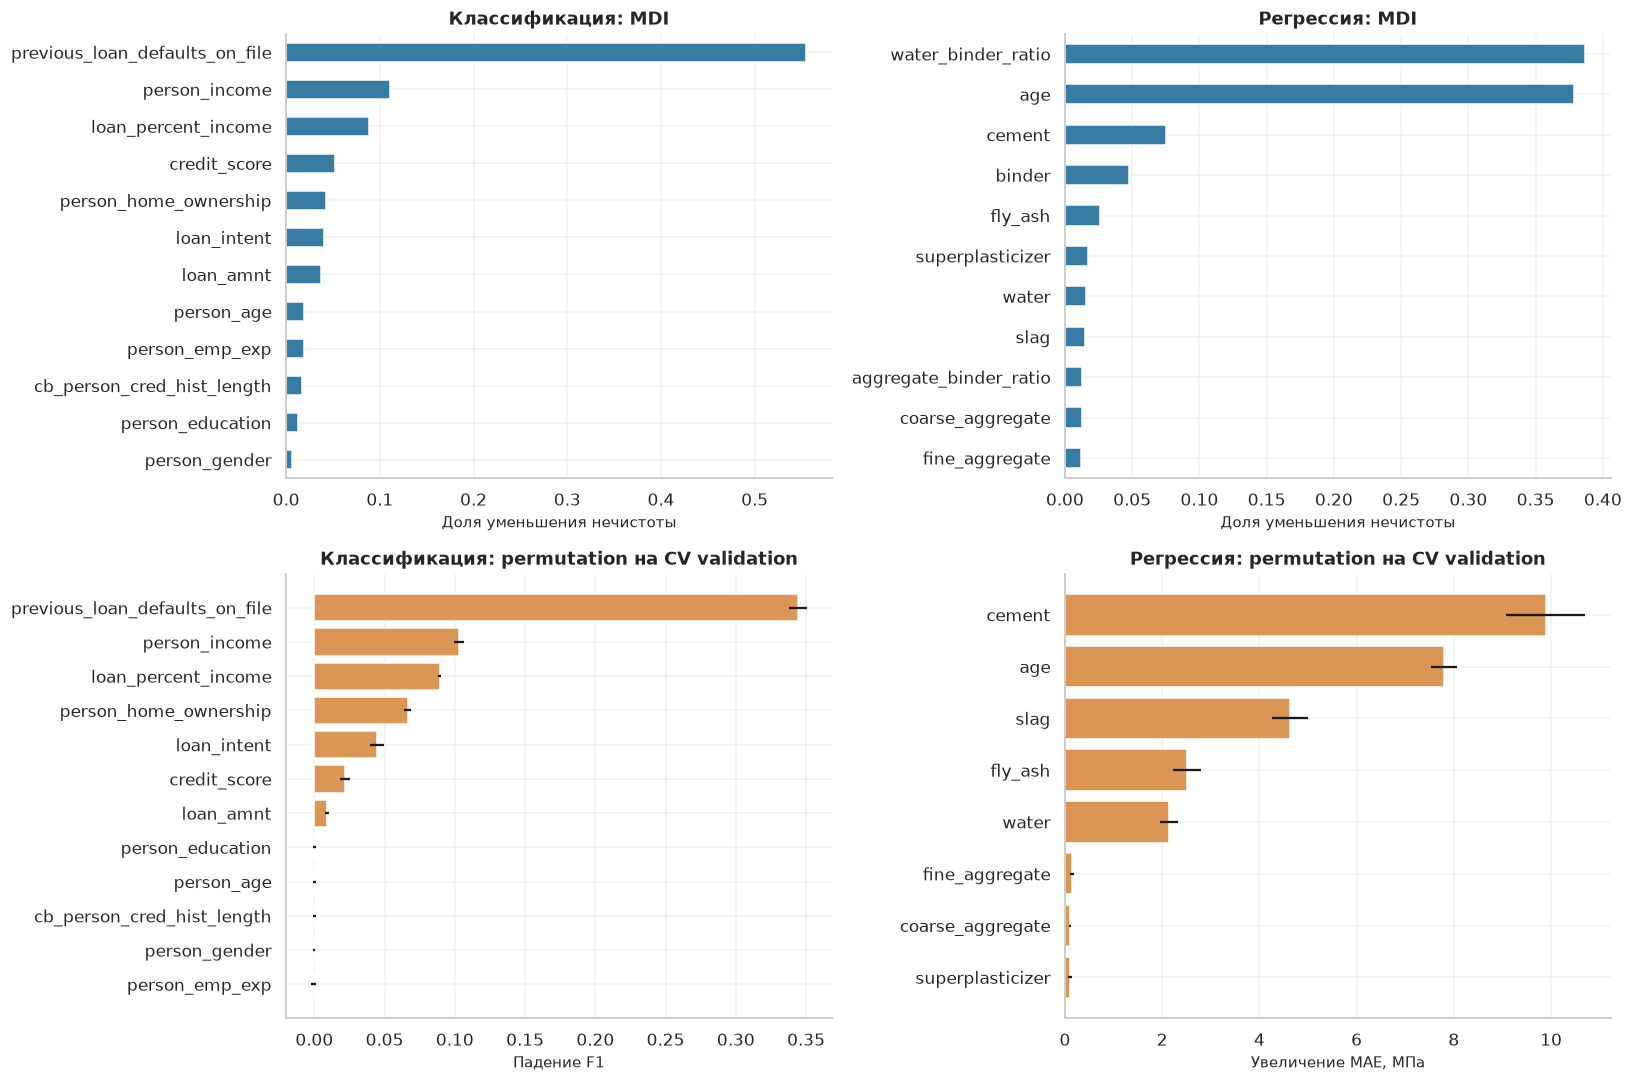

,Задача,feature,importance,std
11,Классификация,previous_loan_defaults_on_file,0.3442,0.0066
3,Классификация,person_income,0.1031,0.0034
8,Классификация,loan_percent_income,0.0893,0.0012
5,Классификация,person_home_ownership,0.0663,0.0025
7,Классификация,loan_intent,0.0447,0.0049


,Задача,feature,importance,std
12,Регрессия,cement,9.8870,0.8084
19,Регрессия,age,7.8057,0.2660
13,Регрессия,slag,4.6210,0.3687
14,Регрессия,fly_ash,2.5122,0.2798
15,Регрессия,water,2.1353,0.1833


In [26]:
# Важности и их визуализация не влияют на выбор модели.
importance_rows, permutation_rows = [], []
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for col, (task, t) in enumerate(tasks.items()):
    pipe = fitted[task, "sklearn_improved"]
    names = pipe.named_steps["preprocess"].get_feature_names_out()
    transformed = pipe.named_steps["features"].transform(t["X_train"]).columns
    grouped = {}
    for name, value in zip(names, pipe.named_steps["model"].feature_importances_):
        short = name.split("__", 1)[1]
        original = next((c for c in CATEGORICAL if short.startswith(c+"_")), short)
        grouped[original] = grouped.get(original, 0.) + value
    mdi = pd.Series(grouped).sort_values()
    mdi.tail(12).plot.barh(ax=axes[0,col], color="#387ca3")
    axes[0,col].set(title=TASK_NAMES[task]+": MDI", xlabel="Доля уменьшения нечистоты")
    importance_rows.extend(dict(task=task, feature=k, importance=v) for k,v in grouped.items())
    a,b = t["cv"][0]
    validation_model = clone(pipe).fit(t["X_train"].iloc[a], t["y_train"].iloc[a])
    perm = permutation_importance(validation_model, t["X_train"].iloc[b], t["y_train"].iloc[b],
        scoring=scoring[task], n_repeats=5, random_state=SEED, n_jobs=1)
    order = np.argsort(perm.importances_mean)
    axes[1,col].barh(t["X_train"].columns[order], perm.importances_mean[order],
                    xerr=perm.importances_std[order], color="#db9655")
    axes[1,col].set(title=TASK_NAMES[task]+": permutation на CV validation",
                    xlabel="Падение F1" if task=="classification" else "Увеличение MAE, МПа")
    permutation_rows.extend(dict(task=task, feature=feature, importance=float(mean), std=float(std))
        for feature,mean,std in zip(t["X_train"].columns,perm.importances_mean,perm.importances_std))
plt.tight_layout()
plt.show()
pd.DataFrame(importance_rows).to_csv(RESULTS / "feature_importances.csv", index=False)
pd.DataFrame(permutation_rows).to_csv(RESULTS / "permutation_importances.csv", index=False)
for task in tasks:
    top = pd.DataFrame(permutation_rows).query("task == @task").sort_values("importance", ascending=False).head(5)
    show_table(top, TASK_NAMES[task]+": наиболее важные исходные признаки на validation")

### Неопределённость разностей на test

Для улучшенный минус исходный sklearn и своя минус sklearn после улучшений посчитаю
парные percentile bootstrap-интервалы (500 повторов). Классификация ресэмплирует строки;
регрессия — **целые рецептуры** с возвращением, сохраняя все возраста выбранной смеси.
В каждом повторе сравниваются одни и те же выбранные объекты для двух моделей.

Интервал условен относительно уже обученных моделей и данного holdout. Он не учитывает
случайность обучения и множественный выбор гиперпараметров. Зависимость синтетических
кредитных объектов может занижать оценённую неопределённость. Если интервал пересекает ноль,
наблюдаемого изменения недостаточно для уверенного вывода о знаке эффекта.

In [27]:
# Парный bootstrap использует готовые test-прогнозы, без переобучения и подбора.
rng = np.random.default_rng(SEED)
interval_rows = []
for task, t in tasks.items():
    truth = t["y_test"].to_numpy()
    if task == "regression":
        group_lookup = t["split"].set_index("row_id").loc[t["X_test"].index,"group_id"].to_numpy()
        groups = np.unique(group_lookup)
        blocks = [np.flatnonzero(group_lookup==g) for g in groups]
    for left,right,label in [("sklearn_improved","sklearn_baseline","Улучшение sklearn"),
                             ("custom_improved","sklearn_improved","Своя минус sklearn после улучшений")]:
        p_left, p_right = predictions[task,left][0], predictions[task,right][0]
        score_fn = f1_score if task=="classification" else mean_absolute_error
        deltas=[]
        for _ in range(500):
            rows = (rng.integers(0,len(truth),len(truth)) if task=="classification" else
                    np.concatenate([blocks[i] for i in rng.integers(0,len(blocks),len(blocks))]))
            deltas.append(score_fn(truth[rows],p_left[rows])-score_fn(truth[rows],p_right[rows]))
        interval_rows.append(dict(task=task, comparison=label,
            delta=score_fn(truth,p_left)-score_fn(truth,p_right),
            lower_95=float(np.quantile(deltas,.025)), upper_95=float(np.quantile(deltas,.975))))
intervals = pd.DataFrame(interval_rows)
intervals.to_csv(RESULTS / "paired_bootstrap.csv", index=False)
show_table(intervals, "Разность F1 / MAE и условный 95% percentile-интервал")

Задача,Сравнение,Изменение,lower_95,upper_95
Классификация,Улучшение sklearn,0.0350,0.0224,0.0488
Классификация,Своя минус sklearn после улучшений,0.0008,-0.0053,0.0074
Регрессия,Улучшение sklearn,-0.6769,-1.3101,-0.0384
Регрессия,Своя минус sklearn после улучшений,-0.0287,-0.1050,0.0596


### Сравнение внутри работы и с предыдущими алгоритмами

Все четыре обязательные пары сравниваются по одной основной метрике:
улучшенный и исходный sklearn, своя и sklearn до улучшения, своя и sklearn после улучшения,
своя после и до переноса техник. Далее добавлю улучшенные решения №1–3.
Перед объединением проверю SHA данных, разбиения, цель и набор исходных входов.

In [28]:
# Сравню варианты внутри работы, затем добавлю улучшенный KNN для ориентира.
comparison_rows, previous_rows = [], []
pairs = [("sklearn_improved", "sklearn_baseline", "Улучшение sklearn"),
         ("custom_baseline", "sklearn_baseline", "Своя и sklearn: исходные"),
         ("custom_improved", "sklearn_improved", "Своя и sklearn: улучшенные"),
         ("custom_improved", "custom_baseline", "Улучшение своей модели")]

for task in tasks:
    m = metrics[metrics.task == task].set_index("model")
    metric = "f1" if task == "classification" else "mae"
    for left, right, label in pairs:
        comparison_rows.append({"task": task, "comparison": label,
                                "metric": "F1" if metric == "f1" else "MAE, МПа",
                                "delta": m.loc[left, metric] - m.loc[right, metric]})
    for number in [1, 2, 3, 4]:
        frame = metrics if number == 4 else pd.read_csv(ROOT / f"lab_{number}" / "results" / "metrics.csv")
        row = frame[(frame.task == task) & (frame.model == "sklearn_improved")].iloc[0]
        for field, expected in [("split_sha", tasks[task]["split_sha"]),
                                ("dataset_sha", tasks[task]["spec"]["sha256"]),
                                ("protocol_id", tasks[task]["spec"]["protocol_id"]),
                                ("feature_set", ",".join(tasks[task]["X_train"].columns))]:
            assert row[field] == expected
        previous_rows.append({"lab": number, "task": task, "algorithm": row.algorithm,
                              "metric": "F1" if metric == "f1" else "MAE, МПа", "Значение": row[metric]})
show_table(pd.DataFrame(comparison_rows), "Изменение основных метрик")
show_table(pd.DataFrame(previous_rows), "Улучшенные sklearn из работ №1–4")
show_table(metrics[["task", "model", "fit_seconds", "predict_seconds"]].reset_index(drop=True), "Время всего Pipeline")

Задача,Сравнение,Метрика,Изменение
Классификация,Улучшение sklearn,F1,0.0350
Классификация,Своя и sklearn: исходные,F1,0.0031
Классификация,Своя и sklearn: улучшенные,F1,0.0008
Классификация,Улучшение своей модели,F1,0.0327
Регрессия,Улучшение sklearn,"MAE, МПа",-0.6769
Регрессия,Своя и sklearn: исходные,"MAE, МПа",-0.0747
Регрессия,Своя и sklearn: улучшенные,"MAE, МПа",-0.0287
Регрессия,Улучшение своей модели,"MAE, МПа",-0.6308


Работа,Задача,Алгоритм,Метрика,Значение
1,Классификация,KNN,F1,0.6960
2,Классификация,LogisticRegression,F1,0.7157
3,Классификация,DecisionTreeClassifier,F1,0.7376
4,Классификация,RandomForestClassifier,F1,0.7757
1,Регрессия,KNN,"MAE, МПа",4.4187
2,Регрессия,LinearRegression,"MAE, МПа",4.8704
3,Регрессия,DecisionTreeRegressor,"MAE, МПа",4.4701
4,Регрессия,RandomForestRegressor,"MAE, МПа",3.9766


Задача,Модель,"Обучение, с","Прогноз, с"
Классификация,Dummy,0.0420,0.0077
Классификация,sklearn · исходная,1.9706,0.0684
Регрессия,Dummy,0.0028,0.0012
Регрессия,sklearn · исходная,0.1949,0.0074
Классификация,sklearn · улучшенная,7.8687,0.0958
Регрессия,sklearn · улучшенная,0.4454,0.0132
Классификация,своя · исходная,35.7200,0.9441
Регрессия,своя · исходная,7.4143,0.0826
Классификация,своя · улучшенная,139.6668,1.1938
Регрессия,своя · улучшенная,20.8185,0.1761


### Итоговые графики качества

Отдельно покажу F1 и MAE для четырёх вариантов леса, затем результаты улучшенных
моделей из всех выполненных работ. Метрики разных задач не объединяются в одну оценку.
Сравниваются полные решения, поскольку подходящая предобработка у алгоритмов различается.

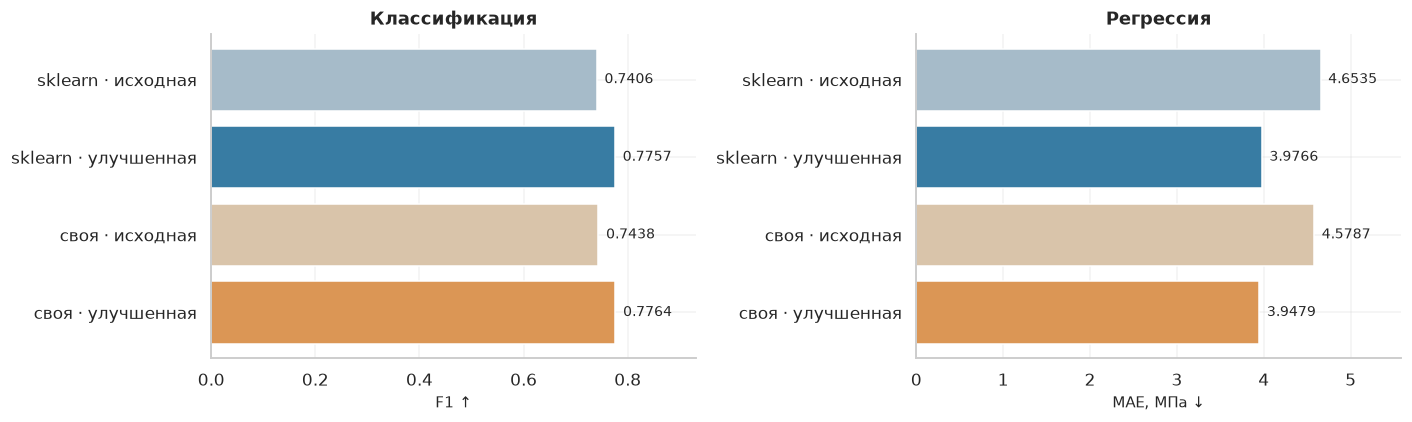

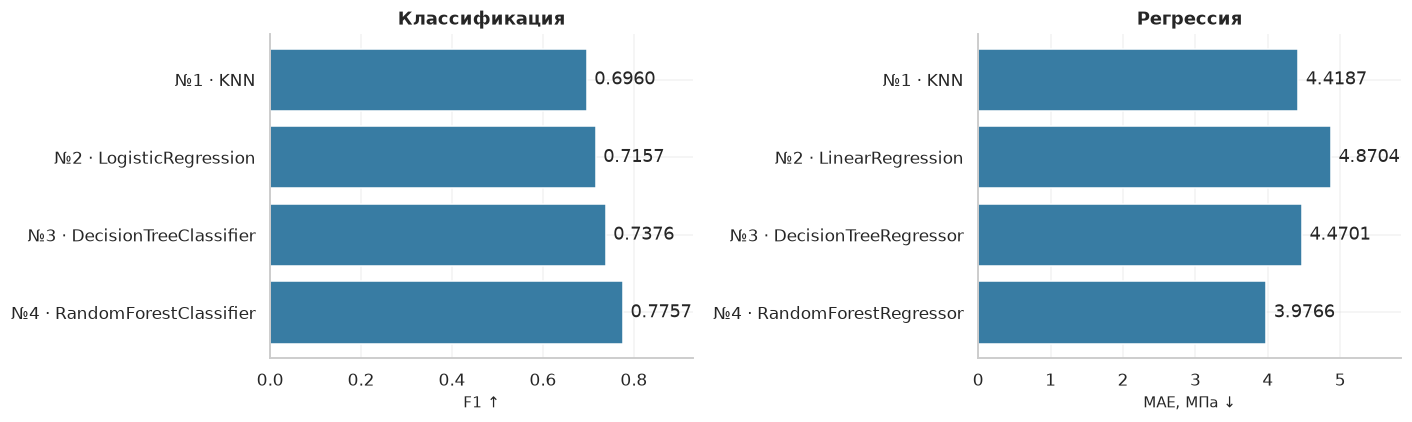

In [29]:
# Подписи значений позволяют увидеть небольшие разности без чтения шкалы.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, task, metric in zip(axes, tasks, ["f1", "mae"]):
    group = metrics[(metrics.task==task)&(metrics.stage!="dummy")]
    bars = ax.barh([MODEL_NAMES[n] for n in group.model], group[metric],
                   color=["#a6bbc9","#387ca3","#d9c4aa","#db9655"])
    ax.bar_label(bars, fmt="%.4f", padding=5, fontsize=9)
    ax.set(title=TASK_NAMES[task], xlabel="F1 ↑" if metric=="f1" else "MAE, МПа ↓")
    ax.set_xlim(0,group[metric].max()*1.2)
    ax.invert_yaxis()
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1,2,figsize=(13,4))
previous = pd.DataFrame(previous_rows)
for ax,task in zip(axes,tasks):
    group=previous.query("task == @task")
    bars=ax.barh([f"№{row.lab} · {row.algorithm}" for row in group.itertuples()],group["Значение"])
    ax.bar_label(bars,fmt="%.4f",padding=5)
    ax.set(title=TASK_NAMES[task],xlabel="F1 ↑" if task=="classification" else "MAE, МПа ↓")
    ax.set_xlim(0,group["Значение"].max()*1.2)
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 6. Выводы и воспроизводимость

### Выводы по каждому обязательному этапу

Следующая ячейка формирует выводы из текущих результатов: baseline, эффект улучшения
sklearn, отличие своей исходной реализации, перенос техник и сравнение улучшенных вариантов.
Знаки разностей одинаковы во всех таблицах: для F1 полезен рост, для MAE — снижение.

In [30]:
# Все утверждения о качестве опираются на результаты этого запуска.
for task in tasks:
    metric = "f1" if task == "classification" else "mae"
    title = "F1" if task == "classification" else "MAE, МПа"
    m = metrics[metrics.task == task].set_index("model")
    config = selected[task]
    old, improved = m.loc["sklearn_baseline", metric], m.loc["sklearn_improved", metric]
    own_old, own_new = m.loc["custom_baseline", metric], m.loc["custom_improved", metric]
    better = improved > old if task == "classification" else improved < old
    own_better = own_new > own_old if task == "classification" else own_new < own_old
    base_cv = hypotheses[(hypotheses.task == task) & (hypotheses["mode"] == "raw")].iloc[0].cv_mean
    display(Markdown(
        f"**{TASK_NAMES[task]}.** Исходный sklearn: **{title} = {old:.5f}**, "
        f"улучшенный: **{improved:.5f}**; изменение **{improved-old:+.5f}**. "
        f"На данном test {'получено улучшение' if better else 'улучшения не получено'}. "
        f"CV-score изменился с **{base_cv:.5f}** до **{config['cv_score']:.5f}** "
        f"(для регрессии это отрицательная MAE). Выбраны признаки `{config['mode']}` "
        f"и параметры `{config['params']}`.\n\n"
        f"Своя исходная модель: **{own_old:.5f}**, разность со sklearn **{own_old-old:+.5f}**. "
        f"После переноса улучшений своя модель: **{own_new:.5f}**, "
        f"изменение **{own_new-own_old:+.5f}**; {'качество улучшилось' if own_better else 'выигрыша на test нет'}. "
        f"Разность с улучшенным sklearn: **{own_new-improved:+.5f}**. "
        "Различия связаны со случайными bootstrap/признаками, равноценными порогами "
        "и учётом повторяющихся строк в ограничениях узлов."))
    prior = pd.DataFrame(previous_rows).query("task == @task")
    best = prior.sort_values("Значение", ascending=task == "regression").iloc[0]
    display(Markdown(f"Среди улучшенных sklearn работ №1–4 на этом test лучший результат "
                     f"у **{best.algorithm} (№{int(best.lab)})**: **{best['Значение']:.5f}**. "
                     "Предобработка между алгоритмами различается, поэтому сравниваются полные решения."))

**Классификация.** Исходный sklearn: **F1 = 0.74064**, улучшенный: **0.77569**; изменение **+0.03505**. На данном test получено улучшение. CV-score изменился с **0.72813** до **0.76143** (для регрессии это отрицательная MAE). Выбраны признаки `raw` и параметры `{'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 0.7, 'bootstrap': True, 'max_samples': None, 'oob_score': True, 'class_weight': 'balanced_subsample'}`.

Своя исходная модель: **0.74377**, разность со sklearn **+0.00313**. После переноса улучшений своя модель: **0.77644**, изменение **+0.03267**; качество улучшилось. Разность с улучшенным sklearn: **+0.00075**. Различия связаны со случайными bootstrap/признаками, равноценными порогами и учётом повторяющихся строк в ограничениях узлов.

Среди улучшенных sklearn работ №1–4 на этом test лучший результат у **RandomForestClassifier (№4)**: **0.77569**. Предобработка между алгоритмами различается, поэтому сравниваются полные решения.

**Регрессия.** Исходный sklearn: **MAE, МПа = 4.65348**, улучшенный: **3.97659**; изменение **-0.67688**. На данном test получено улучшение. CV-score изменился с **-4.73732** до **-3.99708** (для регрессии это отрицательная MAE). Выбраны признаки `engineered` и параметры `{'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 1.0, 'bootstrap': True, 'max_samples': None, 'oob_score': True}`.

Своя исходная модель: **4.57874**, разность со sklearn **-0.07473**. После переноса улучшений своя модель: **3.94794**, изменение **-0.63081**; качество улучшилось. Разность с улучшенным sklearn: **-0.02866**. Различия связаны со случайными bootstrap/признаками, равноценными порогами и учётом повторяющихся строк в ограничениях узлов.

Среди улучшенных sklearn работ №1–4 на этом test лучший результат у **RandomForestRegressor (№4)**: **3.97659**. Предобработка между алгоритмами различается, поэтому сравниваются полные решения.

### Что показали дополнительные проверки

Соберу содержательные наблюдения по числу деревьев, bootstrap, весам, OOB и неопределённости.
Эти выводы также пересчитываются при повторном запуске и не содержат заранее придуманных оценок.

In [31]:
# Финальные пояснения связывают численные результаты с механизмом случайного леса.
for task in tasks:
    title=TASK_NAMES[task]
    curve=size_results.query("task == @task").groupby("n_estimators").cv_score.mean()
    delta=curve.loc[200]-curve.loc[100]
    display(Markdown(f"**{title}: число деревьев.** Изменение CV-score при 100 → 200 деревьев "
        f"составило **{delta:+.5f}**; на первом этапе выбрано **{chosen_sizes[task]}** деревьев. "
        "Увеличение ансамбля уменьшает случайность усреднения, но само по себе не исправляет смещение модели."))
    control=bootstrap_results.query("task == @task").set_index("experiment")
    details="; ".join(f"{name}: **{control.loc[name,'cv_mean']:.5f}**" for name in control.index)
    display(Markdown(f"**{title}: разнообразие.** CV-score: {details}. "
        "Эффект bootstrap и доли признаков зависит от задачи и силы отдельных деревьев."))
    o=oob_results.query("task == @task and model == 'sklearn_improved'").iloc[0]
    display(Markdown(f"**{title}: OOB.** Покрытие улучшенного sklearn **{o.oob_coverage:.1%}**, "
        f"основной OOB {'F1' if task=='classification' else 'MAE'} **{o.oob_primary:.5f}**. "
        +( "Для новых рецептур ориентиром остаётся GroupKFold, так как построчный OOB может видеть ту же смесь."
           if task=='regression' else "Зависимость синтетических объектов ограничивает выводы о реальных заявках.")))
    interval=intervals.query("task == @task and comparison == 'Улучшение sklearn'").iloc[0]
    crosses=interval.lower_95<=0<=interval.upper_95
    display(Markdown(f"**{title}: разность на test.** Условный интервал улучшенный минус исходный sklearn: "
        f"**[{interval.lower_95:+.5f}; {interval.upper_95:+.5f}]**. "
        +( "Интервал пересекает ноль, поэтому уверенный знак выигрыша не установлен." if crosses else
           "Интервал не пересекает ноль в рамках данного ресэмплинга; неопределённость обучения в него не включена.")))
weights=hypothesis_summary[(hypothesis_summary.task=="classification") & hypothesis_summary.experiment.str.startswith("H6")].iloc[0]
display(Markdown(f"**Веса классов:** средняя парная разность CV F1 balanced_subsample минус обычные веса "
                 f"равна **{weights.delta:+.5f}**. Рост recall при взвешивании не гарантирует роста F1, "
                 "а взвешенные вероятности не следует автоматически считать калиброванными."))

**Классификация: число деревьев.** Изменение CV-score при 100 → 200 деревьев составило **+0.00159**; на первом этапе выбрано **200** деревьев. Увеличение ансамбля уменьшает случайность усреднения, но само по себе не исправляет смещение модели.

**Классификация: разнообразие.** CV-score: baseline: **0.72813**; all_features: **0.74692**; bootstrap_70%: **0.72845**; no_bootstrap: **0.73430**. Эффект bootstrap и доли признаков зависит от задачи и силы отдельных деревьев.

**Классификация: OOB.** Покрытие улучшенного sklearn **100.0%**, основной OOB F1 **0.77048**. Зависимость синтетических объектов ограничивает выводы о реальных заявках.

**Классификация: разность на test.** Условный интервал улучшенный минус исходный sklearn: **[+0.02235; +0.04880]**. Интервал не пересекает ноль в рамках данного ресэмплинга; неопределённость обучения в него не включена.

**Регрессия: число деревьев.** Изменение CV-score при 100 → 200 деревьев составило **+0.05088**; на первом этапе выбрано **200** деревьев. Увеличение ансамбля уменьшает случайность усреднения, но само по себе не исправляет смещение модели.

**Регрессия: разнообразие.** CV-score: baseline: **-4.73732**; all_features: **-4.73732**; bootstrap_70%: **-4.83950**; no_bootstrap: **-5.65207**. Эффект bootstrap и доли признаков зависит от задачи и силы отдельных деревьев.

**Регрессия: OOB.** Покрытие улучшенного sklearn **100.0%**, основной OOB MAE **3.19447**. Для новых рецептур ориентиром остаётся GroupKFold, так как построчный OOB может видеть ту же смесь.

**Регрессия: разность на test.** Условный интервал улучшенный минус исходный sklearn: **[-1.31008; -0.03837]**. Интервал не пересекает ноль в рамках данного ресэмплинга; неопределённость обучения в него не включена.

**Веса классов:** средняя парная разность CV F1 balanced_subsample минус обычные веса равна **+0.00667**. Рост recall при взвешивании не гарантирует роста F1, а взвешенные вероятности не следует автоматически считать калиброванными.

### Сохранение протокола

Сохраню версии, источники, SHA разбиений, полный отбор и настройки алгоритмов,
включая явное отличие реализации bootstrap. Общая сводка автоматически читает `metrics.csv`.
Прогнозы с исходными row_id позволяют независимо пересчитать метрики и парные сравнения.

In [32]:
# Протокол связывает результаты с данными, CV и точными настройками.
reference=json.loads((ROOT/"lab_1/results/protocol.json").read_text())
protocol={"lab":4,"seed":SEED,"cv_folds":3,"selected":selected,
    "baseline":{task:baseline_params(task) for task in tasks},
    "selection":"train-only staged CV: raw size curve, then joint representation/hyperparameter search plus baseline candidate",
    "size_candidates":[10,30,100,200],"chosen_sizes":chosen_sizes,
    "classification_threshold":.5,"classification_tie":"first class (0)",
    "criteria":{"classification":"gini","regression":"squared_error"},
    "oob_usage":"diagnostic only; not group-disjoint and not full-pipeline CV",
    "custom_bootstrap":"materialized duplicate rows; min_samples counts repetitions, unlike sklearn weighted unique rows",
    "seed_robustness":[7,21,42],"paired_bootstrap_repeats":500,
    "datasets":reference["datasets"],
    "versions":{"python":platform.python_version(),"numpy":np.__version__,"pandas":pd.__version__,"sklearn":sklearn.__version__}}
(RESULTS/"protocol.json").write_text(json.dumps(protocol,ensure_ascii=False,indent=2))
print("Сохранены метрики, CV, прогнозы, разбиения, OOB, важности, интервалы и протокол в",RESULTS)

Сохранены метрики, CV, прогнозы, разбиения, OOB, важности, интервалы и протокол в /home/sergey/workspace/vkr/lab_4/results


### Итог проведённых экспериментов

**Предобработка и подбор.** Scaling изменил CV F1 всего на −0,00033, а CV MAE — примерно
на +0,009 МПа. Log сам по себе также не дал существенного эффекта. Новые отношения состава
помогли бетону: CV MAE снизилась с **4,730 до 4,020 МПа** относительно log-представления.
Для заявок эти отношения снизили CV F1 на **0,00380**, поэтому выбраны исходные признаки.
Средняя парная разность CV F1 с `balanced_subsample` составила **+0,00667**.
Это результат проверки гипотез, а не основание ожидать такого же эффекта на любом наборе.

**Классификация.** После CV-подбора F1 sklearn выросла с **0,74064 до 0,77569**.
Precision снизилась с **84,78% до 74.12%**, recall выросла с **65,75% до 81.35%**:
модель стала находить больше одобрений ценой дополнительных ложных одобрений.
Выбраны 200 деревьев, исходные признаки, лист от 5 объектов, `max_features=0.7`
и `balanced_subsample`. Веса и ограничение листа здесь меняют весь алгоритм обучения;
рост F1 нельзя приписать одному параметру без сопоставимой проверки.

**Регрессия.** MAE sklearn снизилась с **4,65348 до 3,97659 МПа**, RMSE —
с **6,64751 до 5,71237 МПа**; R² вырос с **0,86305 до 0,89887**.
Выбраны engineered-признаки, 200 деревьев, все признаки в узле и лист от 1 объекта,
без ограничения глубины. Основной выигрыш на CV обеспечили признаки состава.
Отказ от bootstrap увеличил исходную CV MAE с **4,737 до 5,652 МПа**:
усреднение одинаково обученных глубоких деревьев теряет пользу разнообразия.

**Собственная реализация.** Перенос техник улучшил F1 с **0,74377 до 0,77644**,
MAE — с **4,57874 до 3,94794 МПа**. Улучшенные реализации близки по основным метрикам,
но не взаимозаменяемы по отдельным решениям: у своего классификатора precision **76,57%**,
recall **78,75%**, тогда как у sklearn эти показатели **74,12% / 81,35%**.
Парные условные интервалы для своя минус sklearn включают ноль по обеим задачам:
**[−0,00530; +0,00745] F1** и **[−0,10501; +0,05964] МПа**.
Небольшое преимущество своей модели в точечных оценках не доказывает устойчивого превосходства.

**OOB и интерпретация.** Все train-строки получили OOB-прогнозы. Для улучшенного бетона
OOB MAE **3,19447 МПа** заметно ниже групповой CV MAE **3,99708 МПа**;
построчный OOB может видеть другие возраста той же рецептуры и не заменяет GroupKFold.
В заявках по MDI и permutation importance выделяется `previous_loan_defaults_on_file`.
У бетона MDI выделяет воду/вяжущие и возраст; при перемешивании исходных столбцов —
цемент и возраст. Список отличается, потому что MDI рассматривает также созданные признаки,
а перемешивание цемента пересчитывает зависимые отношения. Это не причинные эффекты.

**Сравнение №1–4.** Улучшенный sklearn Random Forest получил лучший F1 и минимальную MAE
среди четырёх выполненных работ на общем test. Для классификации прежний лучший результат
дерева составлял **0,73762**, для регрессии KNN — **4,4187 МПа**.
Это сравнение полных решений на одном holdout; окончательный выбор требует независимой проверки.

### Общий вывод и ограничения

Я выполнил все этапы лабораторной: обучил леса sklearn для двух задач, оценил baseline,
сформулировал и проверил гипотезы на CV, выбрал улучшенные конфигурации, реализовал
случайный лес на NumPy, обучил свою модель до и после переноса улучшений и сравнил
четыре обязательные пары. Численные выводы по каждой задаче и гипотезе приведены выше.
Дополнительно проверены OOB, устойчивость к seed, важности и условная неопределённость разностей.

Лес снижает нестабильность одного дерева за счёт усреднения и разнообразия,
но число деревьев не заменяет содержательных признаков и правильной оценки обобщения.
Scaling сохраняет порядок числовых значений, поэтому для пороговых деревьев его смысл
отличается от KNN и линейных моделей. Log может изменить расположение порога между
наблюдениями; новые отношения дают новые направления разбиений. Полезность каждого
приёма подтверждается или опровергается CV, а не предположением об обязательном улучшении.

Поиск последовательный и ограничен выбранной сеткой. Число деревьев сначала подбиралось
на raw; глобальный оптимум совместного пространства не гарантируется. Лучший CV-score
после перебора оптимистичен. Три фолда и три seed дают описательное исследование,
а не универсальное доказательство превосходства. Времена измерены одним запуском
на одном потоке, включая предобработку, без поиска параметров.

Собственная реализация воспроизводит основные механизмы леса, но отличается от sklearn
генератором случайности и учётом кратностей bootstrap в ограничениях узлов.
Она учебная: один выход, числовой плотный вход после Pipeline, без параллельного обучения,
pruning, монотонных ограничений и обработки пропусков внутри самого дерева.
Полные train используются в обеих реализациях; расхождения не скрываются подгонкой к test.

Holdout общий уже для четырёх работ и служит исследовательским ориентиром.
Для окончательного выбора алгоритма нужен новый независимый holdout или вложенная CV.
Кредитный набор синтетический; историческое одобрение не является риском дефолта.
Разделение бетона исключает точные рецептуры между train и test, но близкие смеси
могут оставаться зависимыми. OOB не обеспечивает разделение по рецептурам,
а MDI и permutation importance не устанавливают причинность.

### Повторный запуск

Из корня репозитория в общем окружении Python 3.12:

```bash
python run_notebooks.py --labs 4
python -m pytest -q
```

Скрипт выполнит лабораторную №4 и обновит [общее сравнение](../comparison.ipynb).
Можно открыть этот notebook из корня либо `lab_4` и выполнить **Run All**.
Требуются включённые данные и протокол №1; сохранённые метрики №1–3 нужны для общей таблицы.
Весь вычислительный код показан в ячейках; повторно используемые модули находятся в `src`.
Основные эксперименты включают много полных лесов на CV и могут занимать несколько минут.

Данные и лицензии: [описание данных](../lab_1/data/README.md).
Алгоритм: [Breiman (2001)](https://www.stat.berkeley.edu/~breiman/randomforest2001.pdf).
Параметры: [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html),
[RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html).
Выполнены работы **№1–4**; №5 остаётся следующим этапом репозитория.